# Grupo 1 · Áreas quemadas — corrida local en CPU y análisis con 20 escenas
**Complemento de `Grupo_1_quemadas_Prithvi.ipynb`.** Mismo flujo (Prithvi-EO-1.0-100M congelado + Random Forest por parche 16×16), ejecutado en un portátil **sin GPU**.

**Qué aporta este cuaderno**
1. **Reproducción:** repite en CPU la corrida de Colab (20 escenas de entrenamiento / 10 de prueba) y verifica que obtiene las mismas escenas y las mismas métricas.
2. **Prueba ampliada:** evalúa el mismo modelo en 20 escenas de prueba (las 10 de Colab + las 10 siguientes que entrega el mismo procedimiento de selección por orden del archivo, sin mirar resultados).
3. **Análisis pendiente del notebook principal:** convención de agregación (media por escena), comparación con línea base, casos representativos (acierto / FP / FN), errores de borde y de resolución, fragmentos pequeños, firmas espectrales de los errores, un control con bandas espectrales y una curva de aprendizaje 4 → 10 → 20 escenas.

**Qué no cambia:** el módulo `prithvi_taller.py` es copia literal de la celda 4 (+ el parche de la celda 18); misma revisión del modelo, misma lectura/recorte, misma normalización, misma cabeza (RF con hiperparámetros fijos) y mismas métricas.

**Qué cambia:** rutas locales y la fuente de bytes del dataset (una copia local del mismo `hls_burn_scars.tar.gz`, verificada con su SHA-256, en lugar de transmitirlo desde Hugging Face en cada corrida).

**Reglas que se respetan:** las etiquetas de prueba solo se usan para evaluar y analizar; ninguna decisión del método (umbral, hiperparámetro, escenas) se toma mirando prueba. La línea base sale de entrenamiento. Modelo, línea base y controles se evalúan sobre exactamente las mismas posiciones válidas.

> **Para integrar al notebook principal:** las secciones 5 a 11 usan solo variables de ese notebook (`pairs`, `samples`, `prepared`, `model`, `device`, `head`, `majority`, `OUT`). Hay que pegar la **celda portátil de utilidades** (la segunda de la sección 0) y luego las secciones 5 a 11 después de la evaluación del notebook principal (sección 7, «Evaluar el modelo y la línea base»), o después de sus controles si ya existen. Se probó así, ejecutando el notebook principal completo con esas celdas insertadas.

> **Para correr con 40 o 60 escenas:** basta cambiar `NTRAIN` en la sección 0 y dejar `NTEST = 20`. Las tablas, las figuras y la curva de aprendizaje se recalculan, pero **los textos de interpretación describen la corrida con `NTRAIN = 20`** y habría que actualizarlos. **Ya se hizo:** la curva con 40 y 60 escenas está en `curva_mas_imagenes.ipynb`, con sus propias interpretaciones.

### Resumen para el grupo
| Pregunta | Respuesta con evidencia de este cuaderno |
|---|---|
| ¿Corre en un portátil sin GPU? | **Sí.** Con un i5-1035G1 de 4 núcleos, 8 GB de RAM y sin GPU, el encoder tarda ≈0.45 s por imagen y el pico de RAM es de 1.2–1.6 GB. El cuaderno completo tardó entre 6 y 31 minutos según la carga del equipo (sección 12). A eso se suma una descarga única de 2.65 GB. Las corridas de 40–60 escenas tampoco necesitan Colab Pro ni GPU. |
| ¿Se reproduce la corrida de Colab? | **Sí.** Se seleccionan las mismas escenas (incluso se leen los mismos 1 873 315 840 bytes comprimidos), con los mismos soportes y métricas a ±0.004 (sección 5). |
| ¿Qué hay que corregir en el notebook principal? | Su tabla final usa **agregado por píxel** (F1 0.85), pero el enunciado pide **media por escena**. Con esa convención, las mismas 10 escenas dan F1 0.64 e IoU 0.55. |
| Resultado con 20 escenas de prueba | **IoU 0.52 [0.40–0.64] y F1 0.63 [0.49–0.76]** (media por escena, IC95 %). La línea base obtiene 0. |
| ¿Aporta Prithvi frente a bandas simples? | En esta configuración no se detecta ventaja. El control espectral obtiene IoU 0.54; la diferencia de Prithvi es −0.02 (IC95 −0.06 a +0.03). |
| ¿Por qué falla? | 1) La salida por parche de 480 m pone un techo de IoU 0.81, y el 46 % de los errores está en parches de borde. 2) En varias escenas lo etiquetado como quemado todavía se ve verde (ρ = −0.74); en T11SLB, la etiqueta es el perímetro final de un incendio que seguía activo en la fecha de la imagen. 3) Hay pocas escenas de entrenamiento del centro-este de EE. UU. 4) Los falsos positivos caen en zonas más oscuras que su entorno, como sombras de ladera. |

## 0. Configuración y utilidades

In [1]:
# --- Configuración de la corrida local (esta celda NO se copia al notebook principal) ---
import os, sys, json, time, platform
from pathlib import Path
import torch
from importlib.metadata import version

HERE = Path.cwd()
if str(HERE) not in sys.path:
    sys.path.insert(0, str(HERE))
from prithvi_taller import (read_sample, train_normalization, normalize, load_prithvi, features,
                            patch_labels, confusion, metrics, save_json, smoke_test)
from soporte_local import ensure_archive, download_data_local, DATASET_REPO, DATASET_REVISION
print(smoke_test())

TASK = 'quemadas'
CLASSES = [0, 1]
NTRAIN, NTEST = 20, 20          # Colab usó 20/10; aquí se amplía la prueba a 20. Para 40/60: cambiar solo NTRAIN.
CURVA_NTRAIN = sorted({4, 10, 20, NTRAIN})   # 4 = valor por defecto de la plantilla del profesor
CACHE = Path(os.environ.get('PRITHVI_CACHE', str(Path.home() / '.cache' / 'prithvi_quemadas')))
OUT = HERE / 'resultados'
TIMES = {}

Tests de métricas superados; NO prueban descarga ni inferencia.


**Celda portátil.** La celda siguiente solo usa lo que ya existe en el notebook principal (`OUT`, `CLASSES`, `model`, `device`, `features`, `patch_labels`, `confusion`, `metrics`). Para llevar el análisis a Colab, se pega esta celda y luego las secciones 5 a 11 después de la celda 23.

In [2]:
# --- Utilidades de análisis (portables al notebook principal) ---
import re, time, warnings
from pathlib import Path
from datetime import date, timedelta
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgb
from matplotlib.patches import Patch
from scipy import ndimage
import rasterio
from rasterio.warp import transform as warp_transform
from sklearn.ensemble import RandomForestClassifier
from IPython.display import display

warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', message='IProgress not found')
if 'TIMES' not in globals():
    TIMES = {}
FIG = OUT / 'figuras'
for d in (OUT, FIG, FIG / 'escenas', OUT / 'escenas'):
    d.mkdir(parents=True, exist_ok=True)

# Paleta validada para daltonismo (azul / naranja / aqua) y tinta neutra para texto y ejes
C = {'modelo': '#2a78d6', 'espectral': '#eb6834', 'base': '#898781',
     'VP': '#1baf7a', 'FP': '#eb6834', 'FN': '#2a78d6', 'VN': '#b5b3ab',
     'ink': '#0b0b0b', 'ink2': '#52514e', 'muted': '#898781', 'grid': '#e1e0d9', 'axis': '#c3c2b7',
     'surface': '#fcfcfb', 'quemado': '#52514e', 'noquemado': '#e9e8e3', 'ignorado': '#ffffff',
     'seq': ['#86b6ef', '#2a78d6', '#104281']}
plt.rcParams.update({
    'figure.facecolor': C['surface'], 'axes.facecolor': C['surface'], 'savefig.facecolor': C['surface'],
    'axes.edgecolor': C['axis'], 'axes.labelcolor': C['ink2'], 'axes.titlecolor': C['ink'],
    'xtick.color': C['axis'], 'ytick.color': C['axis'], 'xtick.labelcolor': C['ink2'], 'ytick.labelcolor': C['ink2'],
    'text.color': C['ink'], 'grid.color': C['grid'], 'grid.linewidth': 0.6, 'axes.axisbelow': True,
    'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 9.5, 'axes.titlesize': 10.5,
    'legend.frameon': False, 'figure.dpi': 100, 'savefig.dpi': 150, 'savefig.bbox': 'tight'})

def scene_id(path):
    """'subsetted_512x512_HLS.S30.T10TEK.2018340.v1.4_merged.tif' -> 'T10TEK.2018340' (tile MGRS . año + día juliano)."""
    m = re.search(r'HLS\.S30\.(T\w{5})\.(\d{7})', Path(path).name)
    return f'{m.group(1)}.{m.group(2)}'

def doy_to_date(code):
    return date(int(code[:4]), 1, 1) + timedelta(days=int(code[4:]) - 1)

def stretch(a):
    a = a.copy()
    for c in range(a.shape[2]):
        v = a[:, :, c]; ok = np.isfinite(v)
        if ok.any():
            lo, hi = np.percentile(v[ok], [2, 98]); a[:, :, c] = np.clip((v - lo) / max(hi - lo, 1e-6), 0, 1)
    return np.nan_to_num(a)

def display_rgb(x):    # color verdadero (rojo, verde, azul), igual que en el notebook principal
    return stretch(x[[2, 1, 0], 0].transpose(1, 2, 0))

def display_false(x):  # falso color SWIR2-NIR-rojo: cicatriz rojiza/morada, vegetación verde, agua oscura
    return stretch(x[[5, 3, 2], 0].transpose(1, 2, 0))

def mask_rgb(y):
    out = np.zeros(y.shape + (3,))
    out[y == 1] = to_rgb(C['quemado']); out[y == 0] = to_rgb(C['noquemado']); out[y < 0] = to_rgb(C['ignorado'])
    return out

def error_rgb(x, y, pred, alpha=0.85):
    g = display_rgb(x).mean(axis=2)
    out = np.repeat((0.35 + 0.6 * g)[..., None], 3, axis=2)        # fondo gris claro (la escena)
    for cat, m in [('VP', (y == 1) & (pred == 1)), ('FP', (y == 0) & (pred == 1)), ('FN', (y == 1) & (pred == 0))]:
        out[m] = (1 - alpha) * out[m] + alpha * np.array(to_rgb(C[cat]))
    out[y < 0] = to_rgb(C['ignorado'])
    return out

LEG_ERR = [Patch(color=C['VP'], label='Quemado detectado (VP)'), Patch(color=C['FP'], label='Falso positivo (FP)'),
           Patch(color=C['FN'], label='Falso negativo (FN)'), Patch(facecolor=C['ignorado'], edgecolor=C['axis'], label='Ignorado (−1)')]
LEG_MASK = [Patch(color=C['quemado'], label='Quemado (1)'), Patch(color=C['noquemado'], label='No quemado (0)'),
            Patch(facecolor=C['ignorado'], edgecolor=C['axis'], label='Ignorado (−1)')]

def to_grid(a):
    """(..., 224, 224) -> (..., 14, 14, 256): bloques 16×16 en el mismo orden que patch_labels y los tokens."""
    s = a.shape[:-2]
    return a.reshape(*s, 14, 16, 14, 16).swapaxes(-3, -2).reshape(*s, 14, 14, 256)

def up(grid):
    return np.repeat(np.repeat(grid, 16, axis=0), 16, axis=1)

def boot_ci(v, B=10000, seed=0):
    """IC95 % de la media por escena: bootstrap remuestreando ESCENAS (no píxeles)."""
    v = np.asarray(v, float); v = v[np.isfinite(v)]
    if len(v) == 0:
        return np.array([np.nan, np.nan])
    idx = np.random.default_rng(seed).integers(0, len(v), size=(B, len(v)))
    return np.percentile(v[idx].mean(axis=1), [2.5, 97.5])

def region(sid):
    """Agrupación geográfica por zona UTM del tile MGRS: 10–13 = Oeste (lon < −102°), 14–18 = Centro-Este."""
    return 'Oeste' if int(sid[1:3]) <= 13 else 'Centro-Este'

def indices(x_raw):
    """Índices espectrales por píxel a partir de reflectancia (bandas: azul, verde, rojo, NIR B8A, SWIR1, SWIR2)."""
    b, g, r, nir, sw1, sw2 = x_raw[:, 0]
    with np.errstate(invalid='ignore', divide='ignore'):
        return {'NBR': (nir - sw2) / (nir + sw2), 'NDVI': (nir - r) / (nir + r), 'NBR2': (sw1 - sw2) / (sw1 + sw2),
                'NIR (B8A)': nir, 'SWIR2': sw2, 'Brillo visible': (b + g + r) / 3}

def haversine_km(lat1, lon1, lat2, lon2):
    p1, p2 = np.radians(lat1), np.radians(lat2)
    a = np.sin((p2 - p1) / 2)**2 + np.cos(p1) * np.cos(p2) * np.sin(np.radians(lon2 - lon1) / 2)**2
    return 2 * 6371.0 * np.arcsin(np.sqrt(a))

# Mismo flujo que las celdas 21 y 23 del notebook principal, en funciones reutilizables
def extract(rows):
    return [features(model, device, x) for x, _ in rows]

def train_head(F_train, rows_train):
    feats, targets = [], []
    for f, (_, y) in zip(F_train, rows_train):
        lab = patch_labels(y); v = lab >= 0
        feats.append(f[v]); targets.append(lab[v])
    X_, Y_ = np.concatenate(feats), np.concatenate(targets)
    h = RandomForestClassifier(n_estimators=80, max_depth=10, class_weight='balanced', random_state=42, n_jobs=2)
    return h.fit(X_, Y_), X_, Y_

def train_majority(rows_raw):
    lab = np.concatenate([y[y >= 0] for _, y in rows_raw])
    values, counts = np.unique(lab, return_counts=True)
    return int(values[np.argmax(counts)]), dict(zip(values.tolist(), counts.tolist()))

def predict_grid(h, f):
    return h.predict(f.reshape(-1, f.shape[-1])).reshape(14, 14)

## 1. Equipo y versiones (procedencia de la ejecución)

In [3]:
def ram_gb():
    try:
        import ctypes
        class MEMSTAT(ctypes.Structure):
            _fields_ = [('dwLength', ctypes.c_ulong), ('dwMemoryLoad', ctypes.c_ulong)] + \
                       [(n, ctypes.c_ulonglong) for n in ['ullTotalPhys', 'ullAvailPhys', 'ullTotalPageFile', 'ullAvailPageFile',
                                                         'ullTotalVirtual', 'ullAvailVirtual', 'ullAvailExtendedVirtual']]
        m = MEMSTAT(); m.dwLength = ctypes.sizeof(MEMSTAT)
        ctypes.windll.kernel32.GlobalMemoryStatusEx(ctypes.byref(m))
        return m.ullTotalPhys / 1024**3, m.ullAvailPhys / 1024**3
    except Exception:
        info = dict(l.split(':', 1) for l in Path('/proc/meminfo').read_text().splitlines())
        kb = lambda k: float(info[k].split()[0]) / 1024**2
        return kb('MemTotal'), kb('MemAvailable')

def peak_ram_gb():
    """Pico de memoria de este proceso (Windows: PeakWorkingSetSize; Linux: ru_maxrss)."""
    try:
        import ctypes
        from ctypes import wintypes
        class PMC(ctypes.Structure):
            _fields_ = [('cb', wintypes.DWORD), ('PageFaultCount', wintypes.DWORD)] + \
                       [(n, ctypes.c_size_t) for n in ['PeakWorkingSetSize', 'WorkingSetSize', 'QuotaPeakPagedPoolUsage',
                        'QuotaPagedPoolUsage', 'QuotaPeakNonPagedPoolUsage', 'QuotaNonPagedPoolUsage', 'PagefileUsage', 'PeakPagefileUsage']]
        pmc = PMC(); pmc.cb = ctypes.sizeof(PMC)
        k32 = ctypes.windll.kernel32; k32.GetCurrentProcess.restype = wintypes.HANDLE
        f = ctypes.windll.psapi.GetProcessMemoryInfo
        f.argtypes = [wintypes.HANDLE, ctypes.POINTER(PMC), wintypes.DWORD]
        f(k32.GetCurrentProcess(), ctypes.byref(pmc), pmc.cb)
        return pmc.PeakWorkingSetSize / 1024**3
    except Exception:
        import resource
        return resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024**2

def cpu_name():
    try:
        import winreg
        k = winreg.OpenKey(winreg.HKEY_LOCAL_MACHINE, r'HARDWARE\DESCRIPTION\System\CentralProcessor\0')
        return winreg.QueryValueEx(k, 'ProcessorNameString')[0].strip()
    except Exception:
        try:
            return next(l.split(':', 1)[1].strip() for l in Path('/proc/cpuinfo').read_text().splitlines() if l.startswith('model name'))
        except Exception:
            return platform.processor()

total, free = ram_gb()
hardware = {'cpu': cpu_name(), 'nucleos_logicos': os.cpu_count(), 'ram_total_gb': round(total, 1),
            'ram_disponible_al_iniciar_gb': round(free, 1), 'gpu_cuda': torch.cuda.is_available(),
            'torch_hilos': torch.get_num_threads(), 'python': platform.python_version(), 'so': platform.platform()}
packages = {p: version(p) for p in ['torch', 'torchvision', 'timm', 'numpy', 'scikit-learn', 'scipy', 'rasterio', 'pandas', 'matplotlib']}
display(pd.Series({**hardware, **{'paquete ' + k: v for k, v in packages.items()}}, name='valor').to_frame())

,valor
cpu,Intel(R) Core(TM) i5-1035G1 CPU @ 1.00GHz
nucleos_logicos,8
ram_total_gb,7.7
ram_disponible_al_iniciar_gb,0.7
gpu_cuda,False
torch_hilos,4
python,3.13.5
so,Windows-11-10.0.26300-SP0
paquete torch,2.7.1
paquete torchvision,0.22.1


## 2. Datos: la misma selección que en Colab
Fuente: [ibm-nasa-geospatial/hls_burn_scars](https://huggingface.co/datasets/ibm-nasa-geospatial/hls_burn_scars), revisión fijada `1864285e…`. Se descarga una vez el `.tar.gz` (2.65 GB) y se verifica con el SHA-256 que publica Hugging Face.

La selección replica `subset_archive` del notebook: recorre el archivo **en su orden**, conserva los primeros pares imagen–máscara de cada partición del proveedor (`training` → entrenamiento, `validation` → prueba) y los ordena por nombre. No mira contenido ni resultados. Se ejecuta para cuatro configuraciones: 20/10 (la de Colab, para verificar), 20/20 (la de este análisis) y 4/20 y 10/20 (curva de aprendizaje).

In [4]:
# Escenas que obtuvo Colab (salida de la celda 9 del notebook principal), en formato tile.fecha
COLAB_TRAIN = ['T10TEK.2018340', 'T11SMT.2019294', 'T11TKE.2018215', 'T11TMF.2019312', 'T11TMJ.2018217',
               'T12STC.2020218', 'T12SUH.2020188', 'T12SVC.2019245', 'T12SVD.2018168', 'T12TUK.2020286',
               'T13SFB.2020189', 'T13TCJ.2020200', 'T13TCM.2020250', 'T13TEF.2019109', 'T14SLA.2020193',
               'T15RTM.2020059', 'T15SXA.2018154', 'T16RFT.2019250', 'T16SDB.2018063', 'T17RMJ.2018064']
COLAB_TEST = ['T10TGK.2020285', 'T10TGL.2018215', 'T11TQG.2018221', 'T12SUJ.2019308', 'T14RNV.2018215',
              'T14SKF.2019246', 'T15TVN.2019140', 'T16REV.2019135', 'T16SDC.2018098', 'T18SVJ.2020131']
COLAB_BYTES = 1873315840   # "Bytes comprimidos leídos" que imprimió Colab

t0 = time.perf_counter()
archive = ensure_archive(CACHE)            # descarga única + verificación de tamaño y SHA-256
TIMES['tar_verificacion_s'] = time.perf_counter() - t0
configs = [(20, 10), (NTRAIN, NTEST)] + [(n, NTEST) for n in CURVA_NTRAIN if n != NTRAIN]
sel = {}
for ntr, nte in configs:
    t0 = time.perf_counter()
    p, nbytes = download_data_local(archive, CACHE / 'datos' / f'train{ntr}_test{nte}', ntr, nte)
    sel[(ntr, nte)] = {'pairs': p, 'bytes': nbytes, 's': time.perf_counter() - t0}
pairs = sel[(NTRAIN, NTEST)]['pairs']
ids = {s: [scene_id(im) for im, _ in rows] for s, rows in pairs.items()}
CURVA_IDS = {n: [scene_id(im) for im, _ in sel[(n, NTEST)]['pairs']['train']] for n in CURVA_NTRAIN}
ids_2010 = {s: [scene_id(im) for im, _ in rows] for s, rows in sel[(20, 10)]['pairs'].items()}
checks = {
    'Bytes comprimidos leídos (20/10) idénticos a Colab': sel[(20, 10)]['bytes'] == COLAB_BYTES,
    'Entrenamiento (20) idéntico a Colab': ids_2010['train'] == COLAB_TRAIN,
    'Prueba (10) idéntica a Colab': ids_2010['test'] == COLAB_TEST,
    f'La prueba de este análisis ({NTEST}) contiene las 10 de Colab': set(COLAB_TEST) <= set(ids['test']),
    'Subconjuntos de entrenamiento anidados (' + ' ⊂ '.join(map(str, CURVA_NTRAIN)) + ')':
        all(set(CURVA_IDS[a]) <= set(CURVA_IDS[b]) for a, b in zip(CURVA_NTRAIN, CURVA_NTRAIN[1:])),
}
TIMES['seleccion_por_configuracion_s'] = {f'{a}/{b}': round(v['s'], 1) for (a, b), v in sel.items()}
display(pd.DataFrame([{'train/test': f'{a}/{b}', 'bytes comprimidos leídos': v['bytes'], 'segundos': round(v['s'], 1)}
                      for (a, b), v in sel.items()]))
display(pd.Series(checks, name='verificación').to_frame())
assert all(checks.values()), 'La selección local no coincide con Colab: revisar antes de seguir.'
print('Escenas de prueba nuevas (no estaban en Colab):', [s for s in ids['test'] if s not in COLAB_TEST])
print('Entrenamiento con 4 escenas (valor por defecto de la plantilla):', CURVA_IDS[4])
print('Entrenamiento con 10 escenas:', CURVA_IDS[10])

Bytes comprimidos leidos: 1873315840


Bytes comprimidos leidos: 1916559360


Bytes comprimidos leidos: 1916559360


Bytes comprimidos leidos: 1916559360


,train/test,bytes comprimidos leídos,segundos
0,20/10,1873315840,63.6
1,20/20,1916559360,70.2
2,4/20,1916559360,59.1
3,10/20,1916559360,64.0


,verificación
Bytes comprimidos leídos (20/10) idénticos a Colab,True
Entrenamiento (20) idéntico a Colab,True
Prueba (10) idéntica a Colab,True
La prueba de este análisis (20) contiene las 10 de Colab,True
Subconjuntos de entrenamiento anidados (4 ⊂ 10 ⊂ 20),True


Escenas de prueba nuevas (no estaban en Colab): ['T11SLB.2018197', 'T11SMU.2020299', 'T11TMF.2020217', 'T11TPH.2020249', 'T12RVV.2020320', 'T12SXA.2020247', 'T12TVK.2020308', 'T15TVN.2018135', 'T16SGE.2019100', 'T17SNU.2018129']
Entrenamiento con 4 escenas (valor por defecto de la plantilla): ['T12SUH.2020188', 'T12SVC.2019245', 'T12TUK.2020286', 'T13TCJ.2020200']
Entrenamiento con 10 escenas: ['T11TKE.2018215', 'T11TMF.2019312', 'T12SUH.2020188', 'T12SVC.2019245', 'T12SVD.2018168', 'T12TUK.2020286', 'T13TCJ.2020200', 'T15RTM.2020059', 'T16RFT.2019250', 'T17RMJ.2018064']


{'train': 20, 'test': 20} | lectura y recorte: 4.4 s


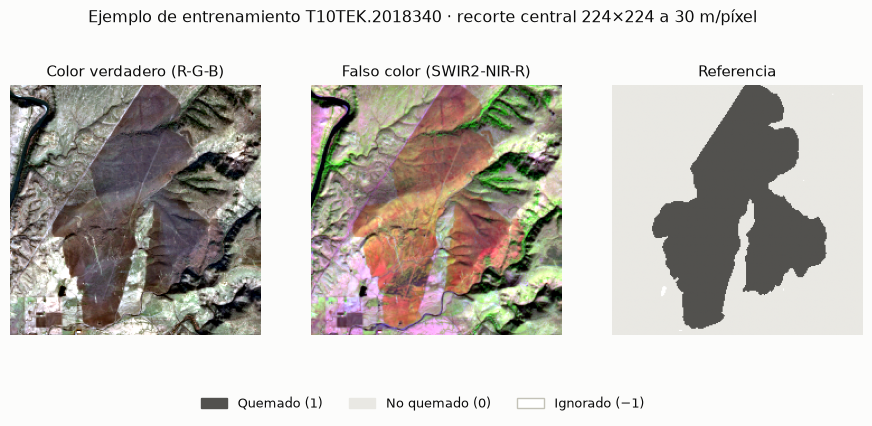

In [5]:
t0 = time.perf_counter()
samples = {split: [read_sample(TASK, im, lab) for im, lab in rows] for split, rows in pairs.items()}
TIMES['lectura_s'] = time.perf_counter() - t0
for split, rows in samples.items():
    for x, y in rows:
        assert x.shape == (6, 1, 224, 224) and y.shape == (224, 224)
        if not np.isin(y[y >= 0], CLASSES).all():
            raise ValueError('Etiqueta fuera de leyenda; revisar la versión.')
print({s: len(r) for s, r in samples.items()}, '| lectura y recorte:', round(TIMES['lectura_s'], 1), 's')

x0, y0 = samples['train'][0]
fig, ax = plt.subplots(1, 3, figsize=(11, 3.9))
for a, img, t in zip(ax, [display_rgb(x0), display_false(x0), mask_rgb(y0)],
                     ['Color verdadero (R-G-B)', 'Falso color (SWIR2-NIR-R)', 'Referencia']):
    a.imshow(img); a.set_title(t); a.axis('off')
fig.legend(handles=LEG_MASK, loc='lower center', ncol=3, bbox_to_anchor=(0.5, -0.05))
fig.suptitle(f'Ejemplo de entrenamiento {ids["train"][0]} · recorte central 224×224 a 30 m/píxel', y=1.01)
fig.savefig(FIG / '01_exploracion.png'); plt.show()

### 2.1 Metadatos, distribución de clases y calidad (responde la actividad de la celda 12)

In [6]:
meta_rows = []
for split, rows in pairs.items():
    for i, ((im, lab), (x, y)) in enumerate(zip(rows, samples[split])):
        sid = scene_id(im)
        with rasterio.open(im) as f:
            arr = f.read(masked=True).astype(np.float32).filled(np.nan)
            crs, b, res_m, dtype, nodata_img = f.crs, f.bounds, f.res[0], f.dtypes[0], f.nodata
        with rasterio.open(lab) as f:
            full = f.read(1, masked=True).astype(np.int64).filled(-1)
            lab_dtype, lab_vals = f.dtypes[0], np.unique(f.read(1))
        full = np.where(np.isfinite(arr).all(0) & (arr != -9999).all(0), full, -1)
        lon, lat = warp_transform(crs, 'EPSG:4326', [(b.left + b.right) / 2], [(b.bottom + b.top) / 2])
        r0, c0 = (full.shape[0] - 224) // 2, (full.shape[1] - 224) // 2       # recorte central que usa read_sample
        b224 = (b.left + c0 * res_m, b.top - (r0 + 224) * res_m, b.left + (c0 + 224) * res_m, b.top - r0 * res_m)
        v = y >= 0
        meta_rows.append({'split': split, 'i': i, 'escena': sid, 'tile': sid[:6], 'fecha': doy_to_date(sid[7:]),
                          'region': region(sid), 'lat': round(lat[0], 3), 'lon': round(lon[0], 3), 'crs': crs.to_string(),
                          'res_m': round(res_m, 3),
                          'tipo_imagen': dtype, 'nodata_imagen': nodata_img, 'tipo_mascara': lab_dtype,
                          'valores_mascara': tuple(lab_vals.tolist()), 'px_validos_224': int(v.sum()),
                          'px_ignorados_224': int((~v).sum()), 'prev_quemado_224': (y == 1).sum() / max(v.sum(), 1),
                          'prev_quemado_512': (full == 1).sum() / max((full >= 0).sum(), 1),
                          'px_ignorados_512': int((full < 0).sum()), 'bounds': tuple(b), 'bounds_224': b224})
meta = pd.DataFrame(meta_rows)
print('Proyecciones (UTM por tile):', meta.crs.nunique(), '| resolución (m):', meta.res_m.unique().tolist(),
      '| tipo imagen:', meta.tipo_imagen.unique().tolist(), '| nodata imagen:', meta.nodata_imagen.unique().tolist())
print('Tipo máscara:', meta.tipo_mascara.unique().tolist(), '| valores presentes en las máscaras 512×512:',
      sorted(set(v for t in meta.valores_mascara for v in t)))
print('Fechas de adquisición:', meta.fecha.min(), 'a', meta.fecha.max(), '| años:', sorted({f.year for f in meta.fecha}))

def class_table(split):
    lab = np.stack([y for _, y in samples[split]])
    patches = np.stack([patch_labels(y) for _, y in samples[split]])
    return {'escenas': len(lab), 'px no quemado (0)': int((lab == 0).sum()), 'px quemado (1)': int((lab == 1).sum()),
            'px ignorado (−1)': int((lab < 0).sum()), '% quemado (de válidos)': 100 * (lab == 1).sum() / (lab >= 0).sum(),
            'parches 16×16 clase 0': int((patches == 0).sum()), 'parches 16×16 clase 1': int((patches == 1).sum()),
            'parches ignorados (<50 % válidos)': int((patches < 0).sum()),
            'escenas sin quemado': int(sum((y == 1).sum() == 0 for _, y in samples[split])),
            'escenas 100 % quemadas': int(sum((y == 1).sum() == (y >= 0).sum() for _, y in samples[split]))}
dist = pd.DataFrame({s: class_table(s) for s in ['train', 'test']}).T
display(dist.round(1))

crop = meta.groupby('split')[['prev_quemado_224', 'prev_quemado_512']].mean().mul(100).round(1)
crop.columns = ['% quemado en recorte 224 (media escenas)', '% quemado en escena 512 completa']
display(crop)
print(f'El recorte central conserva {224 * 224 / 512**2:.0%} del área de cada escena 512×512.')

BANDS = ['Azul', 'Verde', 'Rojo', 'NIR (B8A)', 'SWIR1', 'SWIR2']
qrows = []
for split in ['train', 'test']:
    stack = np.stack([x[:, 0] for x, _ in samples[split]], axis=1).reshape(6, -1)
    for k, bname in enumerate(BANDS):
        v = stack[k]; ok = np.isfinite(v); q = np.percentile(v[ok], [1, 50, 99])
        qrows.append({'split': split, 'banda': bname, 'p1': q[0], 'mediana': q[1], 'p99': q[2], '% no finito': 100 * (~ok).mean()})
display(pd.DataFrame(qrows).pivot(index='banda', columns='split', values=['p1', 'mediana', 'p99', '% no finito']).loc[BANDS].round(4))

Proyecciones (UTM por tile): 9 | resolución (m): [30.0] | tipo imagen: ['float32'] | nodata imagen: [0.0]
Tipo máscara: ['int16'] | valores presentes en las máscaras 512×512: [-1, 0, 1]
Fechas de adquisición: 2018-03-04 a 2020-11-15 | años: [2018, 2019, 2020]


,escenas,px no quemado (0),px quemado (1),px ignorado (−1),% quemado (de válidos),parches 16×16 clase 0,parches 16×16 clase 1,parches ignorados (<50 % válidos),escenas sin quemado,escenas 100 % quemadas
train,20.0,623558.0,379635.0,327.0,37.8,2445.0,1475.0,0.0,0.0,0.0
test,20.0,738825.0,264021.0,674.0,26.3,2887.0,1032.0,1.0,0.0,1.0


,% quemado en recorte 224 (media escenas),% quemado en escena 512 completa
split,,
test,26.4,11.0
train,37.8,12.9


El recorte central conserva 19% del área de cada escena 512×512.


p1         mediana             p99         % no finito        
split        test   train    test   train    test   train        test   train
banda                                                                        
Azul       0.0129  0.0159  0.0489  0.0586  0.1285  0.1263      0.0672  0.0258
Verde      0.0176  0.0289  0.0689  0.0809  0.1775  0.1739      0.0442  0.0162
Rojo       0.0152  0.0218  0.0838  0.1014  0.2270  0.2359      0.0269  0.0083
NIR (B8A)  0.0125  0.0287  0.1960  0.1930  0.3677  0.3982      0.0040  0.0011
SWIR1      0.0091  0.0116  0.2165  0.2469  0.4238  0.4079      0.0000  0.0049
SWIR2      0.0061  0.0085  0.1621  0.1972  0.3464  0.3749      0.0000  0.0078

,escena de prueba,entrenamiento más cercana,distancia (km),comparte tile con entrenamiento,escena 512 se solapa con entrenamiento,recorte 224 se solapa con entrenamiento
4,T11TMF.2020217,T11TMF.2019312,12.6,True,True,False
0,T10TGK.2020285,T11TKE.2018215,51.4,False,False,False
8,T12SUJ.2019308,T12TUK.2020286,81.3,False,False,False
10,T12TVK.2020308,T12TUK.2020286,106.3,False,False,False
3,T11SMU.2020299,T11SMT.2019294,109.7,False,False,False


Pruebas cuya escena 512 se solapa con entrenamiento: 1 | pruebas cuyo RECORTE 224 (lo que ve el modelo) se solapa con entrenamiento: 0
Pares de prueba en el mismo tile (A, B, ¿escenas 512 se solapan?, ¿recortes 224 se solapan?): [('T15TVN.2018135', 'T15TVN.2019140', True, False)]
Escenas por región: {('test', 'Centro-Este'): 9, ('test', 'Oeste'): 11, ('train', 'Centro-Este'): 6, ('train', 'Oeste'): 14}


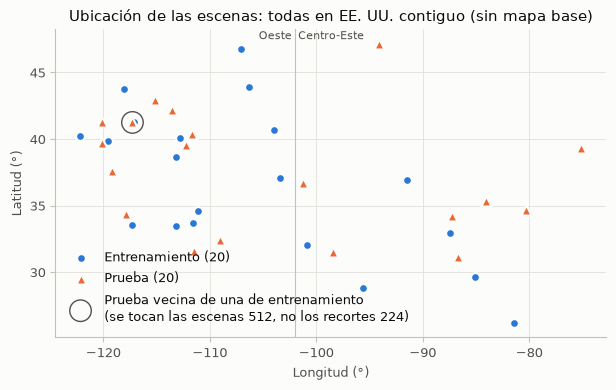

In [7]:
def overlap(b1, b2):
    return not (b1[2] <= b2[0] or b2[2] <= b1[0] or b1[3] <= b2[1] or b2[3] <= b1[1])

tr, te = meta[meta.split == 'train'], meta[meta.split == 'test']
ind = []
for _, r in te.iterrows():
    d = haversine_km(r.lat, r.lon, tr.lat.values, tr.lon.values); j = int(np.argmin(d))
    same = tr[tr.crs == r.crs]
    ind.append({'escena de prueba': r.escena, 'entrenamiento más cercana': tr.iloc[j].escena, 'distancia (km)': round(float(d[j]), 1),
                'comparte tile con entrenamiento': r.tile in set(tr.tile),
                'escena 512 se solapa con entrenamiento': any(overlap(r.bounds, b) for b in same.bounds),
                'recorte 224 se solapa con entrenamiento': any(overlap(r.bounds_224, b) for b in same.bounds_224)})
ind = pd.DataFrame(ind).sort_values('distancia (km)')
display(ind.head(5))
rep_tiles = te[te.duplicated('tile', keep=False)]
pairs_test = [(a.escena, b.escena, overlap(a.bounds, b.bounds), overlap(a.bounds_224, b.bounds_224))
              for k, a in rep_tiles.iterrows() for l, b in rep_tiles.iterrows() if k < l and a.tile == b.tile]
print('Pruebas cuya escena 512 se solapa con entrenamiento:', int(ind['escena 512 se solapa con entrenamiento'].sum()),
      '| pruebas cuyo RECORTE 224 (lo que ve el modelo) se solapa con entrenamiento:', int(ind['recorte 224 se solapa con entrenamiento'].sum()))
print('Pares de prueba en el mismo tile (A, B, ¿escenas 512 se solapan?, ¿recortes 224 se solapan?):', pairs_test)
print('Escenas por región:', meta.groupby(['split', 'region']).size().to_dict())

fig, ax = plt.subplots(figsize=(7.6, 4.0))
ax.scatter(tr.lon, tr.lat, s=40, color=C['modelo'], marker='o', label=f'Entrenamiento ({len(tr)})', edgecolor=C['surface'], linewidth=1.5)
ax.scatter(te.lon, te.lat, s=52, color=C['espectral'], marker='^', label=f'Prueba ({len(te)})', edgecolor=C['surface'], linewidth=1.5)
ov = te[te.escena.isin(ind.loc[ind['escena 512 se solapa con entrenamiento'], 'escena de prueba'])]
if len(ov):
    ax.scatter(ov.lon, ov.lat, s=240, facecolor='none', edgecolor=C['ink2'], linewidth=1,
               label='Prueba vecina de una de entrenamiento\n(se tocan las escenas 512, no los recortes 224)')
ax.axvline(-102, color=C['axis'], lw=0.8)
ax.text(-102.3, 47.5, 'Oeste', ha='right', fontsize=8, color=C['ink2']); ax.text(-101.7, 47.5, 'Centro-Este', ha='left', fontsize=8, color=C['ink2'])
ax.set_xlabel('Longitud (°)'); ax.set_ylabel('Latitud (°)'); ax.grid(True); ax.set_aspect(1.25)
ax.set_title('Ubicación de las escenas: todas en EE. UU. contiguo (sin mapa base)')
ax.legend(loc='lower left')
fig.savefig(FIG / '02_ubicacion_escenas.png'); plt.show()

**Lectura de los datos (responde la actividad de la celda 12)**
- **Producto y canales:** HLS v1.4 derivado de Sentinel-2 (S30), con 6 bandas en reflectancia 0–1 (`float32`) en este orden: azul, verde, rojo, NIR estrecho (B8A), SWIR1 y SWIR2. La resolución es de 30 m y la proyección es la UTM de cada tile MGRS (9 zonas distintas). El *nodata* declarado de la imagen es 0, así que esos píxeles se leen como no finitos y se ignoran. La máscara es `int16`: 1 = cicatriz, 0 = no quemado, −1 = sin dato (ignorado). Hay una sola fecha por escena, posterior al incendio, entre el 4-mar-2018 y el 15-nov-2020, y todas las escenas están en EE. UU. contiguo.
- **Desbalance:** hay 37.8 % de píxeles quemados en entrenamiento y 26.3 % en prueba (recortes 224). En la escena completa de 512×512 la proporción baja a 11–13 %. **El recorte central sobrerrepresenta lo quemado**, porque las escenas están centradas en la cicatriz.
- **Qué se pierde con el recorte central:** solo se conserva el 19 % del área de cada escena. Se pierde la mayor parte del fondo (y con él muchos posibles falsos positivos), los bordes externos de las cicatrices grandes y el contexto. Las métricas del recorte no equivalen a las de la escena completa.
- **Calidad:** hay muy pocos píxeles ignorados (327 en entrenamiento y 674 en prueba) y menos de 0.07 % de valores no finitos por banda. Una escena de prueba está 100 % quemada en el recorte (T10TGK.2020285) y ninguna carece de positivos, así que no hizo falta aplicar la convención de escenas sin positivos.
- **Independencia:** se conserva la partición del proveedor (*training* / *validation*). Ningún recorte de prueba se solapa con uno de entrenamiento. T11TMF.2020217 (prueba) es vecina de T11TMF.2019312 (entrenamiento, otro año, a 12.6 km): sus escenas 512 se tocan en el borde, pero los recortes que ve el modelo no. T15TVN 2018 y 2019 (ambas de prueba) son del mismo lugar en años consecutivos.
- **Representatividad:** 14 de las 20 escenas de entrenamiento son del oeste (zonas UTM 10–13) y solo 6 del centro-este; en la prueba hay 11 del oeste y 9 del centro-este.

## 3. Normalización sin fuga de prueba
Igual que la celda 14: media y desviación por banda con **solo** los píxeles válidos de entrenamiento. Se compara con los valores que imprimió Colab.

In [8]:
mean, std = train_normalization(samples['train'])
prepared = {split: [(normalize(x, mean, std), y) for x, y in rows] for split, rows in samples.items()}
save_json(OUT / 'normalizacion.json', {'method': 'train_zscore_by_band', 'mean': mean.tolist(), 'std': std.tolist()})
COLAB_MEAN = [0.05949525, 0.08366273, 0.10327961, 0.19505522, 0.24320912, 0.19280952]
COLAB_STD = [0.02866969, 0.03636152, 0.05242738, 0.0720992, 0.08832543, 0.08634797]
print('Media train:', mean, '| STD train:', std)
if sorted(ids['train']) == sorted(COLAB_TRAIN):
    rel = max(np.max(np.abs(mean - COLAB_MEAN) / np.abs(COLAB_MEAN)), np.max(np.abs(std - COLAB_STD) / np.abs(COLAB_STD)))
    print(f'Diferencia relativa máxima frente a Colab: {rel:.1e} (float32 tiene ~1e-7 de precisión; '
          f'¿iguales a precisión float32? {np.allclose(mean, COLAB_MEAN, rtol=1e-6, atol=0) and np.allclose(std, COLAB_STD, rtol=1e-6, atol=0)})')
else:
    print('Comparación con Colab omitida: el entrenamiento no es el de Colab (NTRAIN distinto de 20).')

Media train: [0.05949525 0.08366273 0.10327959 0.19505523 0.2432092  0.1928095 ] | STD train: [0.02866968 0.03636152 0.05242737 0.07209922 0.08832543 0.08634797]
Diferencia relativa máxima frente a Colab: 3.2e-07 (float32 tiene ~1e-7 de precisión; ¿iguales a precisión float32? True)


## 4. Prithvi congelado + Random Forest por parche
Misma revisión del modelo (`7b231fe…`), mismo parche de configuración, mismos hiperparámetros de la cabeza (`n_estimators=80, max_depth=10, class_weight='balanced', random_state=42`). Los embeddings se calculan una vez y se guardan en `F` para reutilizarlos en el análisis (es el mismo cálculo que hace la celda 21 dentro del bucle).

In [9]:
t0 = time.perf_counter()
T = prepared['train'][0][0].shape[1]
model, device, model_info = load_prithvi(CACHE / 'modelo', num_frames=T)
TIMES['carga_modelo_s'] = time.perf_counter() - t0
model_info['checkpoint'] = Path(model_info['checkpoint']).name   # sin rutas locales en la procedencia
n_enc = sum(p.numel() for n, p in model.named_parameters() if not n.startswith(('decoder', 'mask_token')))
provenance = {'task': TASK, 'model': model_info, 'ntrain': NTRAIN, 'ntest': NTEST, 'classes': CLASSES,
              'crop': 'center224_pad_ignore', 'normalization': 'train_zscore_by_band',
              'head': 'RandomForest(n_estimators=80, max_depth=10, class_weight=balanced, random_state=42), patch16 majority, frozen encoder',
              'dataset': {'repo': DATASET_REPO, 'revision': DATASET_REVISION}, 'hardware': hardware, 'packages': packages,
              'ejecucion': 'local en CPU; seleccion de escenas identica a la de Colab'}
save_json(OUT / 'procedencia.json', provenance)
print(model_info)
print(f'Parámetros del encoder usado: {n_enc / 1e6:.1f} M | carga del modelo: {TIMES["carga_modelo_s"]:.1f} s')

{'repo': 'ibm-nasa-geospatial/Prithvi-EO-1.0-100M', 'revision': '7b231fe5b0684e2ddd40c967fbc02e225ef77dc6', 'checkpoint': 'Prithvi_100M.pt', 'device': 'cpu', 'num_frames': 1}
Parámetros del encoder usado: 86.4 M | carga del modelo: 12.7 s


In [10]:
t0 = time.perf_counter()
F = {split: extract(rows) for split, rows in prepared.items()}
TIMES['embeddings_s'] = time.perf_counter() - t0
TIMES['embeddings_s_por_imagen'] = TIMES['embeddings_s'] / sum(len(v) for v in F.values())
t0 = time.perf_counter()
head, X, Y = train_head(F['train'], prepared['train'])
TIMES['rf_entrenamiento_s'] = time.perf_counter() - t0
majority, train_counts = train_majority(samples['train'])
print('Parches de entrenamiento por clase:', dict(zip(*[a.tolist() for a in np.unique(Y, return_counts=True)])), '| Colab: {0: 2445, 1: 1475}')
print('Píxeles válidos de entrenamiento por clase:', train_counts)
print('Línea base constante = clase mayoritaria de ENTRENAMIENTO:', majority)
print(f"Embeddings: {TIMES['embeddings_s']:.1f} s para {sum(len(v) for v in F.values())} imágenes "
      f"({TIMES['embeddings_s_por_imagen']:.2f} s/imagen) | Random Forest: {TIMES['rf_entrenamiento_s']:.1f} s")

Parches de entrenamiento por clase: {0: 2445, 1: 1475} | Colab: {0: 2445, 1: 1475}
Píxeles válidos de entrenamiento por clase: {0: 623558, 1: 379635}
Línea base constante = clase mayoritaria de ENTRENAMIENTO: 0
Embeddings: 17.4 s para 40 imágenes (0.43 s/imagen) | Random Forest: 5.8 s


## 5. Evaluación en 20 escenas de prueba y comparación con la línea base
**Convención principal (enunciado §6): media por escena** de las métricas de la clase quemada (1), cada una calculada sobre las posiciones válidas de su escena. Aparte, y rotulado, se reporta el **agregado por píxel** (suma de matrices de confusión), que es lo que imprimió la corrida de Colab.

- Escena sin positivos en referencia **ni** en predicción → IoU/F1 indefinidos (NaN), se excluyen de la media y se informa cuántas escenas entran.
- Escena con positivos en la referencia pero sin predicciones positivas → precisión = 0 (convención de `metrics`).
- Línea base: predice en todas partes la clase mayoritaria de los píxeles válidos de **entrenamiento** (0). No usa etiquetas de prueba.
- IC95 %: bootstrap remuestreando **escenas** (10 000 réplicas), porque los píxeles de una misma escena no son observaciones independientes.

In [11]:
# Puente para el notebook principal: reconstruye lo que este análisis necesita a partir de sus variables.
if 'ids' not in globals():
    ids = {s: [scene_id(im) for im, _ in rows] for s, rows in pairs.items()}
if 'F' not in globals():
    F = {s: [features(model, device, x) for x, _ in rows] for s, rows in prepared.items()}
if 'COLAB_TEST' not in globals():   # escenas de la corrida original de Colab (20 de entrenamiento, 10 de prueba)
    COLAB_TEST = ['T10TGK.2020285', 'T10TGL.2018215', 'T11TQG.2018221', 'T12SUJ.2019308', 'T14RNV.2018215',
                  'T14SKF.2019246', 'T15TVN.2019140', 'T16REV.2019135', 'T16SDC.2018098', 'T18SVJ.2020131']
if 'COLAB_TRAIN' not in globals():
    COLAB_TRAIN = ['T10TEK.2018340', 'T11SMT.2019294', 'T11TKE.2018215', 'T11TMF.2019312', 'T11TMJ.2018217',
                   'T12STC.2020218', 'T12SUH.2020188', 'T12SVC.2019245', 'T12SVD.2018168', 'T12TUK.2020286',
                   'T13SFB.2020189', 'T13TCJ.2020200', 'T13TCM.2020250', 'T13TEF.2019109', 'T14SLA.2020193',
                   'T15RTM.2020059', 'T15SXA.2018154', 'T16RFT.2019250', 'T16SDB.2018063', 'T17RMJ.2018064']

def evaluate(grids, rows_test, maj, method):
    """Métricas por escena de la clase 1 para `method` y para la línea base, con la misma máscara de válidos."""
    out, mats = [], {method: [], 'linea_base': []}
    for i, (grid, (_, y)) in enumerate(zip(grids, rows_test)):
        for name, p in [(method, up(grid)), ('linea_base', np.full(y.shape, maj, dtype=np.int64))]:
            mat = confusion(y, p, CLASSES); mats[name].append(mat)
            m1 = metrics(mat, CLASSES)[1]
            out.append({'i': i, 'escena': ids['test'][i], 'metodo': name, 'vp': int(mat[1, 1]), 'fp': int(mat[0, 1]),
                        'fn': int(mat[1, 0]), 'vn': int(mat[0, 0]), 'soporte_1': m1['support'], 'iou': m1['iou'],
                        'f1': m1['f1'], 'precision': m1['precision'], 'recall': m1['recall']})
    d = pd.DataFrame(out)
    with np.errstate(invalid='ignore', divide='ignore'):
        d['exactitud'] = (d.vp + d.vn) / (d.vp + d.vn + d.fp + d.fn)
        d['iou_0'] = np.where(d.vn + d.fp + d.fn > 0, d.vn / (d.vn + d.fp + d.fn), np.nan)
    return d, mats

def summarize(df, mats, subset=None):
    rows = []
    for name in df.metodo.unique():
        d = df[df.metodo == name]
        if subset is not None:
            d = d[d.escena.isin(subset)]
        pooled = metrics(sum(mats[name][i] for i in d.i), CLASSES)[1]
        row = {'método': name, 'escenas': len(d), 'escenas con IoU definido': int(d.iou.notna().sum())}
        for col, lab in [('iou', 'IoU'), ('f1', 'F1'), ('precision', 'Precisión'), ('recall', 'Recall')]:
            lo, hi = boot_ci(d[col])
            row[f'{lab} media escena'] = d[col].mean(); row[f'{lab} IC95'] = f'{lo:.3f}–{hi:.3f}'
        for col, lab in [('iou', 'IoU'), ('f1', 'F1'), ('precision', 'Precisión'), ('recall', 'Recall')]:
            row[f'{lab} agregado píxel'] = pooled[col]
        rows.append(row)
    return pd.DataFrame(rows).set_index('método')

t0 = time.perf_counter()
grids = [predict_grid(head, f) for f in F['test']]
per_scene, mats = evaluate(grids, prepared['test'], majority, 'prithvi_rf')
TIMES['evaluacion_s'] = time.perf_counter() - t0
for i, (grid, (_, y)) in enumerate(zip(grids, prepared['test'])):
    np.savez_compressed(OUT / 'escenas' / f'escena_{i:02d}_{ids["test"][i]}.npz', label=y, prediction=up(grid),
                        baseline=np.full(y.shape, majority, dtype=np.int64))

summ20 = summarize(per_scene, mats)
summ10 = summarize(per_scene, mats, subset=set(COLAB_TEST))
print(f'Prueba: {len(ids["test"])} escenas')
display(summ20.round(3))
print('Solo las 10 escenas de Colab')
display(summ10.round(3))

Prueba: 20 escenas


,escenas,escenas con IoU definido,IoU media escena,IoU IC95,F1 media escena,F1 IC95,Precisión media escena,Precisión IC95,Recall media escena,Recall IC95,IoU agregado píxel,F1 agregado píxel,Precisión agregado píxel,Recall agregado píxel
método,,,,,,,,,,,,,,
prithvi_rf,20,20,0.524,0.397–0.643,0.633,0.494–0.757,0.746,0.601–0.874,0.604,0.455–0.743,0.596,0.747,0.891,0.643
linea_base,20,20,0.000,0.000–0.000,0.000,0.000–0.000,0.000,0.000–0.000,0.000,0.000–0.000,0.000,0.000,0.000,0.000


Solo las 10 escenas de Colab


,escenas,escenas con IoU definido,IoU media escena,IoU IC95,F1 media escena,F1 IC95,Precisión media escena,Precisión IC95,Recall media escena,Recall IC95,IoU agregado píxel,F1 agregado píxel,Precisión agregado píxel,Recall agregado píxel
método,,,,,,,,,,,,,,
prithvi_rf,10,10,0.551,0.345–0.740,0.642,0.424–0.834,0.737,0.511–0.920,0.61,0.382–0.817,0.741,0.851,0.914,0.797
linea_base,10,10,0.000,0.000–0.000,0.000,0.000–0.000,0.000,0.000–0.000,0.00,0.000–0.000,0.000,0.000,0.000,0.000


In [12]:
# Verificación de reproducibilidad frente a la corrida de Colab (agregado por píxel, mismas 10 escenas)
COLAB_RES = {'prithvi_rf': {0: {'iou': 0.920455, 'f1': 0.958580, 'precision': 0.941416, 'recall': 0.976381},
                            1: {'iou': 0.739057, 'f1': 0.849952, 'precision': 0.910058, 'recall': 0.797293}},
             'linea_base': {0: {'iou': 0.769384, 'f1': 0.869663, 'precision': 0.769384, 'recall': 1.0},
                            1: {'iou': 0.0, 'f1': 0.0, 'precision': 0.0, 'recall': 0.0}}}
COLAB_SUPPORT = {0: 386046, 1: 115714}
rep = pd.DataFrame()
if sorted(ids['train']) == sorted(COLAB_TRAIN) and set(COLAB_TEST) <= set(ids['test']):
    idx10 = [i for i, s in enumerate(ids['test']) if s in COLAB_TEST]
    rows_rep = []
    for name in ['prithvi_rf', 'linea_base']:
        pooled = metrics(sum(mats[name][i] for i in idx10), CLASSES)
        for c in CLASSES:
            for k in ['iou', 'f1', 'precision', 'recall']:
                rows_rep.append({'método': name, 'clase': c, 'métrica': k, 'Colab (GPU T4)': COLAB_RES[name][c][k],
                                 'esta ejecución': round(float(pooled[c][k]), 6)})
    rep = pd.DataFrame(rows_rep); rep['diferencia'] = (rep['esta ejecución'] - rep['Colab (GPU T4)']).round(6)
    support10 = {c: metrics(sum(mats['prithvi_rf'][i] for i in idx10), CLASSES)[c]['support'] for c in CLASSES}
    print('Soporte (píxeles válidos) en las 10 escenas:', support10, '| Colab:', COLAB_SUPPORT, '| iguales:', support10 == COLAB_SUPPORT)
    print('Máxima diferencia absoluta en métricas:', rep['diferencia'].abs().max())
    display(rep.pivot_table(index=['método', 'clase'], columns='métrica', values='diferencia'))
else:
    print('Comparación con Colab omitida: el entrenamiento no es el de Colab (NTRAIN distinto de 20).')

Soporte (píxeles válidos) en las 10 escenas: {0: 386046, 1: 115714} | Colab: {0: 386046, 1: 115714} | iguales: True
Máxima diferencia absoluta en métricas: 0.003965


métrica                 f1      iou  precision    recall
método     clase                                        
linea_base 0      0.000000  0.00000   0.000000  0.000000
           1      0.000000  0.00000   0.000000  0.000000
prithvi_rf 0      0.000510  0.00094  -0.000090  0.001155
           1      0.001399  0.00212   0.003965 -0.000570

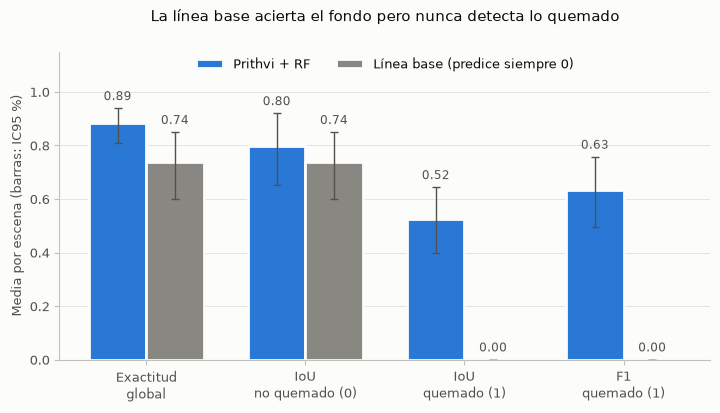

In [13]:
# Gráfico comparativo (TODO de la celda 25): media por escena con IC95 %, 20 escenas de prueba
cols = [('exactitud', 'Exactitud\nglobal'), ('iou_0', 'IoU\nno quemado (0)'), ('iou', 'IoU\nquemado (1)'), ('f1', 'F1\nquemado (1)')]
series = [('prithvi_rf', 'Prithvi + RF', C['modelo']), ('linea_base', 'Línea base (predice siempre 0)', C['base'])]
fig, ax = plt.subplots(figsize=(8.4, 4.0))
w = 0.36
for k, (name, label, color) in enumerate(series):
    d = per_scene[per_scene.metodo == name]
    means = np.array([d[c].mean() for c, _ in cols]); cis = np.array([boot_ci(d[c]) for c, _ in cols])
    xs = np.arange(len(cols)) + (k - 0.5) * w
    ax.bar(xs, means, width=w, color=color, label=label, edgecolor=C['surface'], linewidth=2)
    ax.errorbar(xs, means, yerr=[means - cis[:, 0], cis[:, 1] - means], fmt='none', ecolor=C['ink2'], elinewidth=1, capsize=3)
    for xv, m_, hi in zip(xs, means, cis[:, 1]):
        ax.text(xv, max(hi, m_) + 0.02, f'{m_:.2f}', ha='center', va='bottom', fontsize=8.5, color=C['ink2'])
ax.set_xticks(np.arange(len(cols))); ax.set_xticklabels([l for _, l in cols]); ax.set_ylim(0, 1.15); ax.yaxis.grid(True)
ax.set_ylabel('Media por escena (barras: IC95 %)'); ax.legend(loc='upper center', ncol=2, bbox_to_anchor=(0.5, 1.02))
ax.set_title('La línea base acierta el fondo pero nunca detecta lo quemado', pad=22)
fig.savefig(FIG / '03_modelo_vs_linea_base.png'); plt.show()

**Resultado principal (20 escenas de prueba, media por escena):** Prithvi + RF obtiene **IoU = 0.524** (IC95 % 0.40–0.64) y **F1 = 0.633** (0.49–0.76) en la clase quemada, con precisión 0.746 y recall 0.604. La línea base constante obtiene 0 en todas las métricas de la clase quemada, aunque su exactitud global y su IoU del fondo son 0.74: **una exactitud alta del fondo no implica detectar lo quemado**.

**Reproducibilidad:** en las 10 escenas de Colab el soporte coincide píxel a píxel (386 046 y 115 714) y las métricas difieren como máximo en 0.004 (F1 de la clase quemada: 0.851 aquí y 0.850 en Colab). La diferencia viene de la aritmética de punto flotante de CPU frente a GPU en los embeddings, que cambia algunas divisiones del Random Forest. Es mucho menor que la incertidumbre entre escenas.

**⚠ Convención de agregación:** el F1 = 0.85 que imprime el notebook principal es el **agregado por píxel**. Con la convención del enunciado (media por escena), esas mismas 10 escenas dan **F1 = 0.642 e IoU = 0.551**. La diferencia viene sobre todo de T10TGK.2020285: está 100 % quemada, tiene 50 176 píxeles y F1 0.99, así que domina el agregado. En el informe la media por escena debe ser la métrica principal, y el agregado, si se muestra, debe ir rotulado.

**Prueba ampliada:** con las 10 escenas nuevas el agregado por píxel baja de 0.851 a 0.747, porque entran escenas difíciles como T11SLB.2018197 y T17SNU.2018129. La media por escena casi no cambia (0.642 → 0.633). Los intervalos son anchos: con 10–20 escenas la incertidumbre del F1 es de ±0.13.

## 6. Resultados por escena (trazables por tile y fecha)

,i,escena,fecha,en Colab,% quemado,soporte_1,iou,f1,precision,recall,fp,fn
0,0,T10TGK.2020285,2020-10-11,True,100.000,50176,0.980,0.990,1.000,0.980,0,1024
1,6,T11TQG.2018221,2018-08-09,True,17.072,8566,0.812,0.896,0.865,0.930,1247,597
2,10,T12TVK.2020308,2020-11-03,False,30.072,15087,0.802,0.890,0.931,0.853,959,2222
3,11,T14RNV.2018215,2018-08-03,True,13.142,6594,0.792,0.884,0.937,0.836,373,1079
4,8,T12SUJ.2019308,2019-11-04,True,27.208,13652,0.759,0.863,0.858,0.869,1964,1792
5,1,T10TGL.2018215,2018-08-03,True,18.977,9522,0.693,0.819,0.740,0.916,3058,804
6,13,T15TVN.2018135,2018-05-15,False,18.537,9301,0.672,0.804,0.906,0.723,701,2578
7,19,T18SVJ.2020131,2020-05-10,True,13.586,6817,0.668,0.801,0.962,0.686,187,2140
8,5,T11TPH.2020249,2020-09-05,False,13.006,6526,0.649,0.787,0.665,0.965,3175,229
9,3,T11SMU.2020299,2020-10-25,False,97.506,48274,0.587,0.740,0.995,0.589,144,19836


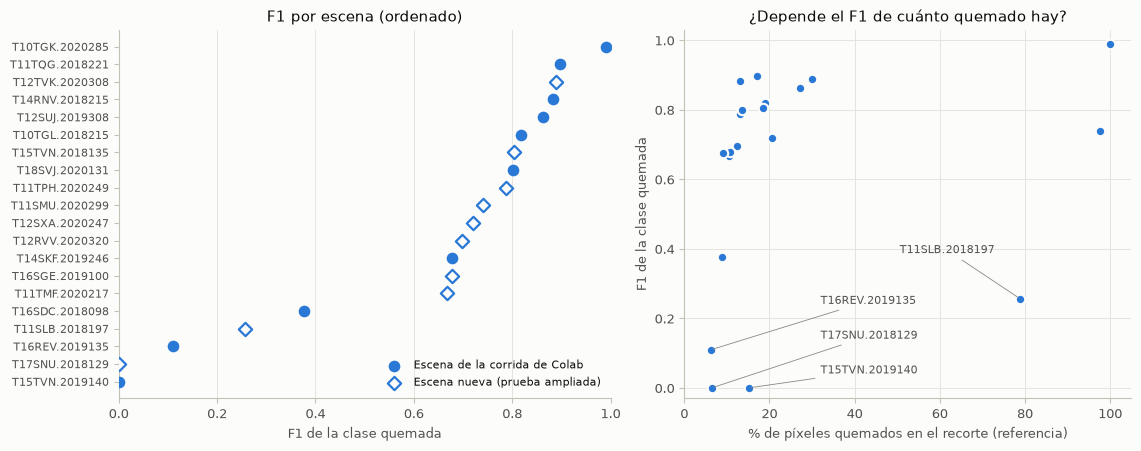

,escenas de entrenamiento,escenas de prueba,F1 media,IoU media,escenas con F1 < 0.4,F1 IC95
región,,,,,,
Centro-Este,6,9,0.481,0.383,4,0.25–0.70
Oeste,14,11,0.757,0.639,1,0.64–0.85


In [14]:
m = per_scene[per_scene.metodo == 'prithvi_rf'].copy()
m['fecha'] = [doy_to_date(s[7:]) for s in m.escena]
m['en Colab'] = m.escena.isin(COLAB_TEST)
m['% quemado'] = [100 * (y == 1).sum() / (y >= 0).sum() for _, y in samples['test']]
tabla_escenas = (m[['i', 'escena', 'fecha', 'en Colab', '% quemado', 'soporte_1', 'iou', 'f1', 'precision', 'recall', 'fp', 'fn']]
                 .sort_values('f1', ascending=False).reset_index(drop=True))
display(tabla_escenas.round(3))

fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.6), gridspec_kw={'width_ratios': [1.1, 1]})
o = m.sort_values('f1')
yy = np.arange(len(o))
for flag, mk, lab in [(True, 'o', 'Escena de la corrida de Colab'), (False, 'D', 'Escena nueva (prueba ampliada)')]:
    s = o['en Colab'].values == flag
    ax[0].scatter(o.f1.values[s], yy[s], marker=mk, s=46, color=C['modelo'] if flag else C['surface'],
                  edgecolor=C['modelo'], linewidth=1.6, label=lab, zorder=3)
ax[0].set_yticks(yy); ax[0].set_yticklabels(o.escena, fontsize=8); ax[0].set_xlim(0, 1); ax[0].xaxis.grid(True)
ax[0].set_xlabel('F1 de la clase quemada'); ax[0].set_title('F1 por escena (ordenado)'); ax[0].legend(loc='lower right', fontsize=8)
ax[1].scatter(m['% quemado'], m.f1, s=46, color=C['modelo'], edgecolor=C['surface'], linewidth=1.5, zorder=3)
low = m.nsmallest(4, 'f1').sort_values(['f1', '% quemado'], ascending=[True, False])
for k, (_, r) in enumerate(low.iterrows()):
    xt, yt, ha = (32, 0.05 + 0.1 * k, 'left') if r['% quemado'] < 50 else (r['% quemado'] - 6, r.f1 + 0.14, 'right')
    ax[1].annotate(r.escena, (r['% quemado'], r.f1), xytext=(xt, yt), textcoords='data', fontsize=8, color=C['ink2'], ha=ha,
                   va='center', arrowprops={'arrowstyle': '-', 'color': C['muted'], 'lw': 0.6})
ax[1].set_xlabel('% de píxeles quemados en el recorte (referencia)'); ax[1].set_ylabel('F1 de la clase quemada')
ax[1].set_xlim(0, 105); ax[1].set_ylim(-0.03, 1.03); ax[1].grid(True); ax[1].set_title('¿Depende el F1 de cuánto quemado hay?')
fig.tight_layout(); fig.savefig(FIG / '04_metricas_por_escena.png'); plt.show()

# Exploratorio: desempeño por región (zona UTM del tile). Se planteó al ver el mosaico; con 9–11 escenas por grupo no es concluyente.
m['región'] = [region(s) for s in m.escena]
reg = m.groupby('región').agg(**{'escenas de prueba': ('f1', 'size'), 'F1 media': ('f1', 'mean'), 'IoU media': ('iou', 'mean'),
                                 'escenas con F1 < 0.4': ('f1', lambda s: int((s < 0.4).sum()))})
reg['F1 IC95'] = ['{:.2f}–{:.2f}'.format(*boot_ci(m.loc[m['región'] == g, 'f1'])) for g in reg.index]
reg.insert(0, 'escenas de entrenamiento', pd.Series([region(s) for s in ids['train']]).value_counts().reindex(reg.index).fillna(0).astype(int))
display(reg.round(3))

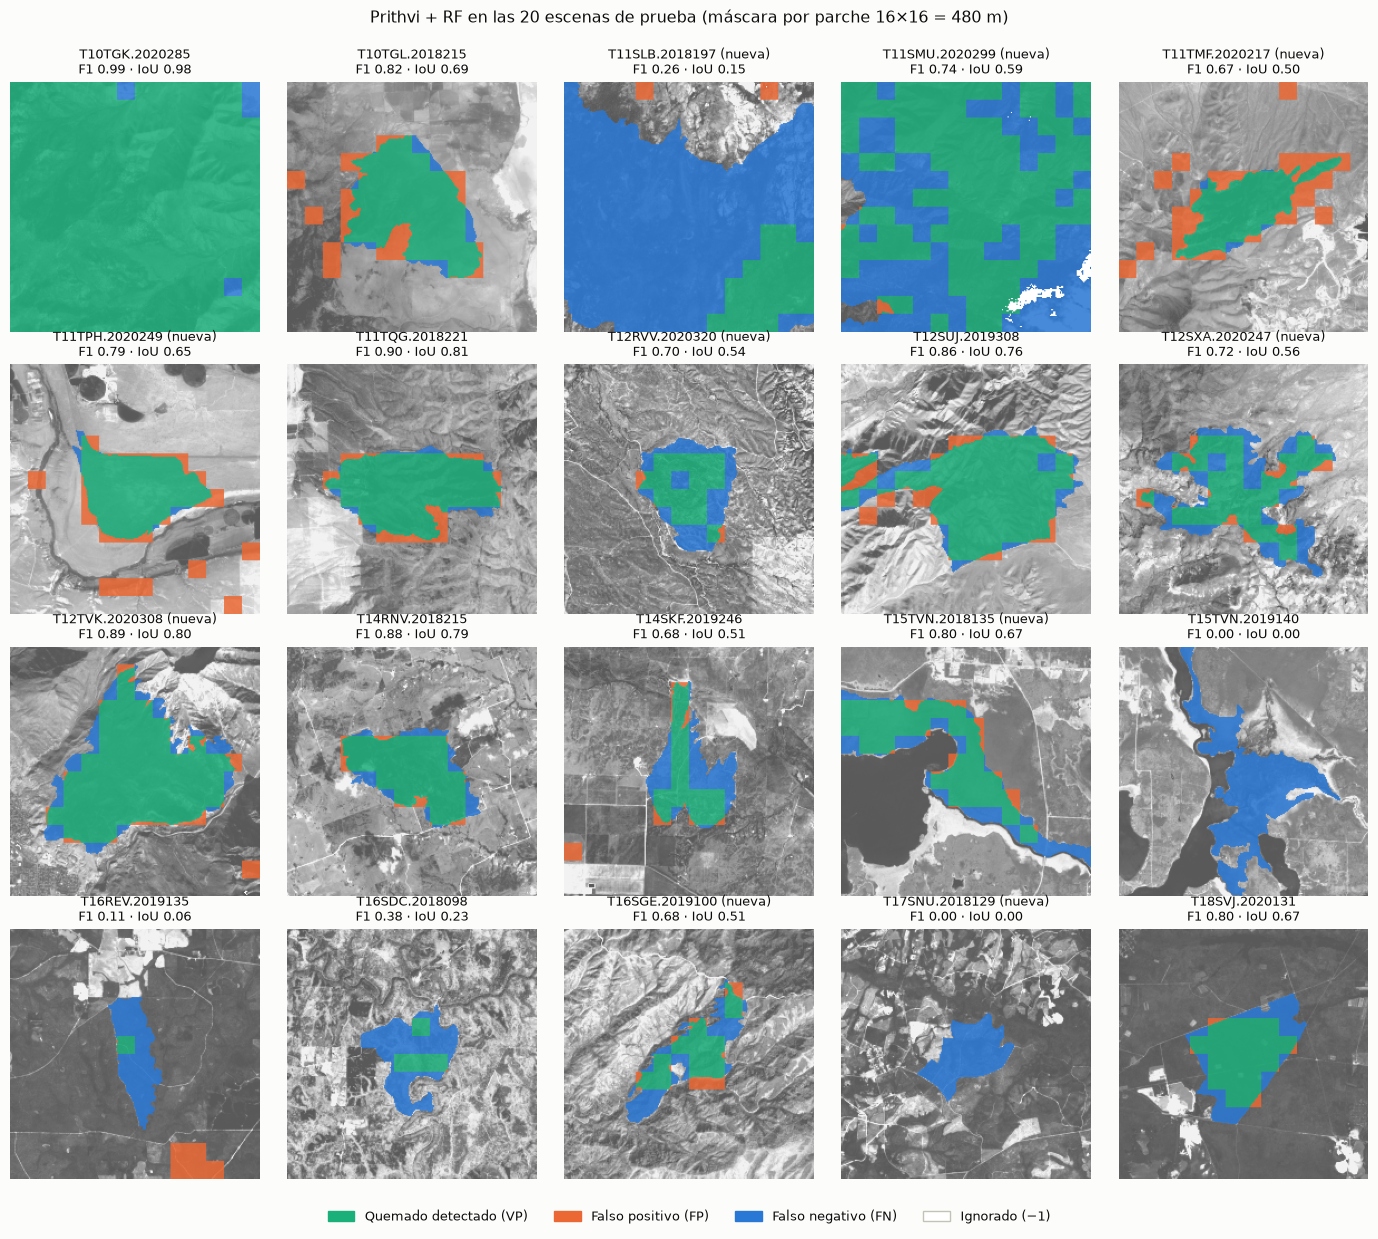

In [15]:
# Mosaico de las 20 escenas de prueba: aciertos y errores sobre la escena en gris
n_te = len(ids['test']); nrow = int(np.ceil(n_te / 5))
fig, axes = plt.subplots(nrow, 5, figsize=(14, 3.05 * nrow), squeeze=False)
for ax in axes.flat[n_te:]:
    ax.axis('off')
for ax, i in zip(axes.flat, range(n_te)):
    x, y = samples['test'][i]
    ax.imshow(error_rgb(x, y, up(grids[i]))); ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values(): s.set_visible(False)
    r = m.set_index('i').loc[i]
    ax.set_title(f"{ids['test'][i]}{'' if r['en Colab'] else ' (nueva)'}\nF1 {r.f1:.2f} · IoU {r.iou:.2f}", fontsize=9)
fig.legend(handles=LEG_ERR, loc='lower center', ncol=4, bbox_to_anchor=(0.5, -0.005))
fig.suptitle(f'Prithvi + RF en las {n_te} escenas de prueba (máscara por parche 16×16 = 480 m)', y=1.0)
fig.tight_layout(rect=(0, 0.03, 1, 1)); fig.savefig(FIG / '05_mosaico_prueba.png'); plt.show()

# Figuras individuales (como 02_resultado_i.png del notebook principal), guardadas sin mostrar
for i in range(len(ids['test'])):
    x, y = samples['test'][i]; pred = up(grids[i])
    f2, a2 = plt.subplots(1, 5, figsize=(16, 3.6))
    for a, img, t in zip(a2, [display_rgb(x), display_false(x), mask_rgb(y), mask_rgb(np.where(y < 0, -1, pred)), error_rgb(x, y, pred)],
                         ['Color verdadero', 'Falso color SWIR2-NIR-R', 'Referencia', 'Prithvi + RF (parche 16)', 'VP / FP / FN']):
        a.imshow(img); a.set_title(t); a.axis('off')
    f2.suptitle(ids['test'][i]); f2.savefig(FIG / 'escenas' / f'resultado_{i:02d}_{ids["test"][i]}.png', dpi=100); plt.close(f2)

- **Rango muy amplio:** el F1 va de 0.99 (T10TGK.2020285) a 0 (T15TVN.2019140 y T17SNU.2018129, donde no se marcó ningún parche como quemado). 15 de las 20 escenas superan F1 = 0.6; el promedio esconde cinco fallas fuertes.
- **No depende de la proporción quemada:** hay fallas con poca cicatriz (6 %) y con mucha (79 %).
- **Por región (exploratorio):** en el oeste (zonas UTM 10–13) el F1 medio es 0.757 (IC95 0.64–0.85), con 1 escena por debajo de 0.4. En el centro-este (zonas 14–18) es 0.481 (0.25–0.70), con 4 escenas por debajo de 0.4. El entrenamiento tiene 14 escenas del oeste y solo 6 del centro-este. Esto es compatible con un **desplazamiento de dominio dentro de EE. UU.** (otros ecosistemas y otros tipos de quema). Pero el agrupamiento se planteó después de ver los resultados y con 9–11 escenas por grupo no es concluyente.

## 7. Casos representativos: acierto, falso positivo y falso negativo
**Regla fijada antes de mirar las imágenes** (para no escoger casos a conveniencia): *acierto* = escena con mayor F1; *falsos positivos* = escena con más píxeles FP (sin repetir la anterior); *falsos negativos* = escena con más píxeles FN (sin repetir las anteriores).

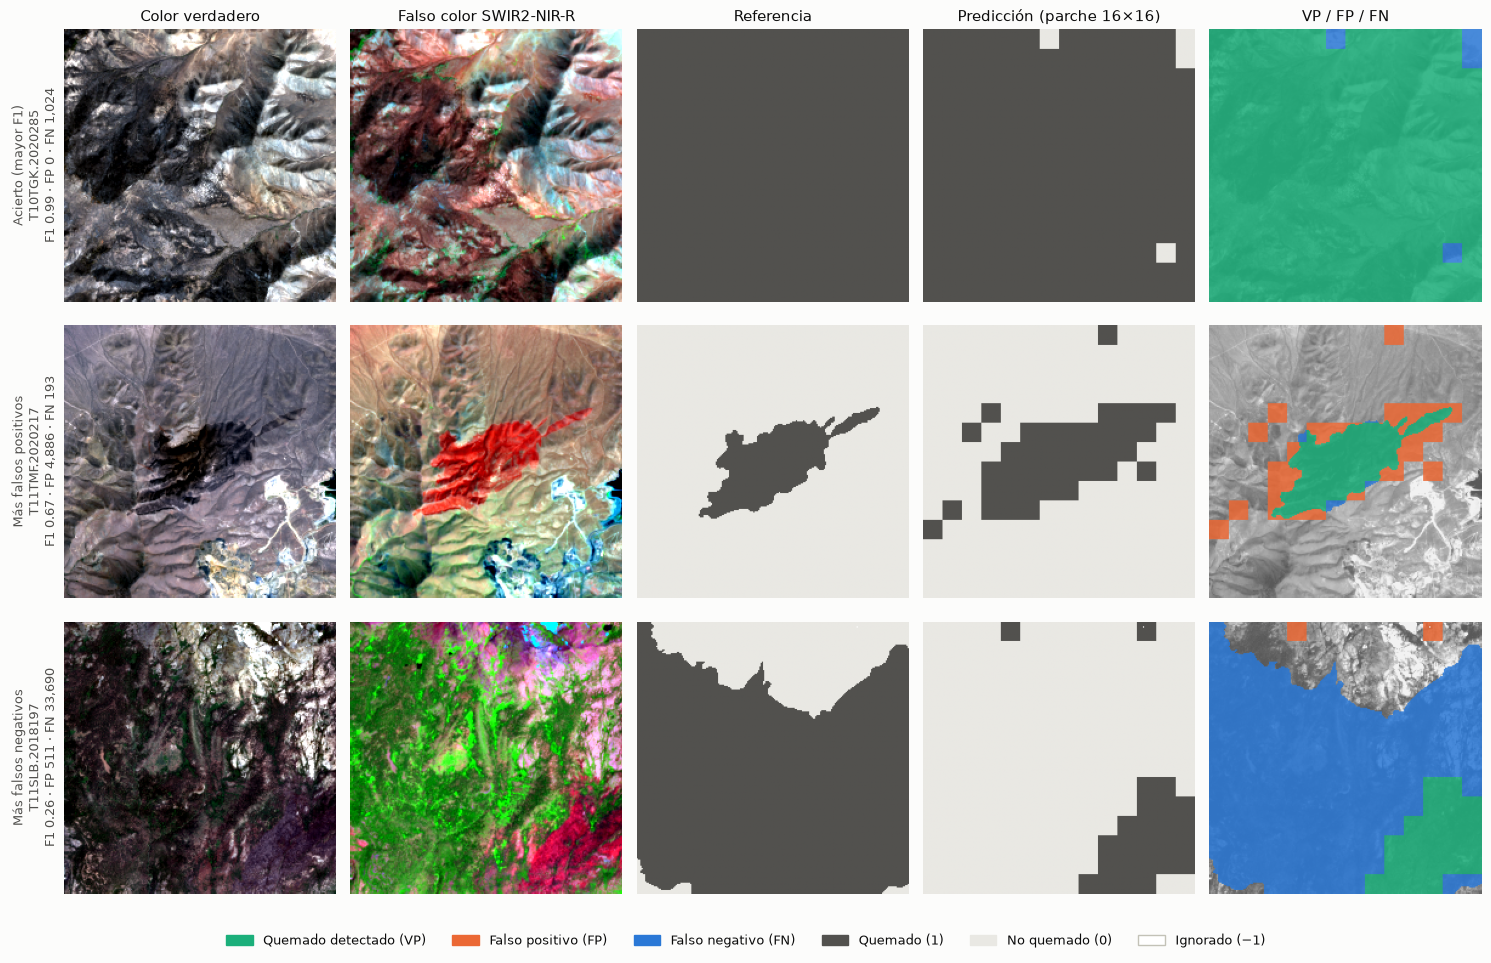

,caso,escena,categoría,píxeles,NBR,NDVI,NIR (B8A),Brillo visible
0,Acierto (mayor F1),T10TGK.2020285,VP,49152,-0.313,0.167,0.103,0.058
1,Acierto (mayor F1),T10TGK.2020285,FN,1024,-0.193,0.189,0.168,0.089
2,Acierto (mayor F1),T10TGK.2020285,FP,0,NaN,NaN,NaN,NaN
3,Acierto (mayor F1),T10TGK.2020285,VN,0,NaN,NaN,NaN,NaN
4,Más falsos positivos,T11TMF.2020217,VP,5098,-0.313,0.157,0.144,0.083
5,Más falsos positivos,T11TMF.2020217,FN,193,-0.241,0.153,0.165,0.097
6,Más falsos positivos,T11TMF.2020217,FP,4886,-0.117,0.144,0.189,0.113
7,Más falsos positivos,T11TMF.2020217,VN,39999,-0.090,0.139,0.200,0.122
8,Más falsos negativos,T11SLB.2018197,VP,5888,-0.072,0.330,0.125,0.049
9,Más falsos negativos,T11SLB.2018197,FN,33690,0.318,0.563,0.202,0.049


In [16]:
mm = m.set_index('i')
acierto = int(mm.f1.idxmax())
caso_fp = int(mm.drop(index=[acierto]).fp.idxmax())
caso_fn = int(mm.drop(index=[acierto, caso_fp]).fn.idxmax())
casos = [('Acierto (mayor F1)', acierto), ('Más falsos positivos', caso_fp), ('Más falsos negativos', caso_fn)]

fig, axes = plt.subplots(3, 5, figsize=(15, 9.6))
titles = ['Color verdadero', 'Falso color SWIR2-NIR-R', 'Referencia', 'Predicción (parche 16×16)', 'VP / FP / FN']
for r_, (title, i) in enumerate(casos):
    x, y = samples['test'][i]; pred = up(grids[i])
    imgs = [display_rgb(x), display_false(x), mask_rgb(y), mask_rgb(np.where(y < 0, -1, pred)), error_rgb(x, y, pred)]
    for c_, img in enumerate(imgs):
        ax = axes[r_, c_]; ax.imshow(img); ax.set_xticks([]); ax.set_yticks([])
        for s in ax.spines.values(): s.set_visible(False)
        if r_ == 0: ax.set_title(titles[c_])
    axes[r_, 0].set_ylabel(f'{title}\n{ids["test"][i]}\nF1 {mm.f1[i]:.2f} · FP {mm.fp[i]:,} · FN {mm.fn[i]:,}', fontsize=9.5)
fig.legend(handles=LEG_ERR[:3] + LEG_MASK, loc='lower center', ncol=6, bbox_to_anchor=(0.5, -0.01))
fig.tight_layout(rect=(0, 0.03, 1, 1)); fig.savefig(FIG / '06_casos_representativos.png'); plt.show()

crow = []
for title, i in casos:
    x, y = samples['test'][i]; pred = up(grids[i]); ix = indices(x)
    for cat, msk in [('VP', (y == 1) & (pred == 1)), ('FN', (y == 1) & (pred == 0)), ('FP', (y == 0) & (pred == 1)), ('VN', (y == 0) & (pred == 0))]:
        crow.append({'caso': title, 'escena': ids['test'][i], 'categoría': cat, 'píxeles': int(msk.sum()),
                     **{k: (float(np.nanmean(ix[k][msk])) if msk.any() else np.nan) for k in ['NBR', 'NDVI', 'NIR (B8A)', 'Brillo visible']}})
casos_tabla = pd.DataFrame(crow)
display(casos_tabla.round(3))

**Acierto: T10TGK.2020285 (norte de California, 11-oct-2020).** El recorte está completamente quemado y el modelo solo pierde 4 parches (1 024 píxeles). En falso color la cicatriz se ve rojiza y homogénea, con NBR mediano de −0.31: una firma de quemado fuerte. Es el caso fácil, y además es el que domina el agregado por píxel.

**Falsos positivos: T11TMF.2020217 (norte de Nevada, 4-ago-2020).** Recall 0.96, pero precisión 0.51. Los FP rodean una cicatriz alargada. De sus 4 886 píxeles FP, 768 son inevitables con parches de 16×16 y 2 070 son decisiones en parches de borde (58 % en total); los otros 2 048 son 8 parches aislados. El NBR de los FP es −0.12, casi igual al del fondo bien clasificado (−0.09): en este paisaje árido, el suelo y el matorral ralo tienen NBR bajo y se parecen a lo quemado. Aquí se suman **la resolución de 480 m y la confusión con suelo o vegetación escasa**.

**Falsos negativos: T11SLB.2018197 (Sierra Nevada, California, 16-jul-2018).** La referencia marca como quemado el 79 % del recorte, pero el modelo solo detecta la esquina sureste. En el área no detectada el NDVI es 0.56 y el NBR +0.32, es decir, vegetación verde; en lo detectado el NBR es −0.07. **La imagen no muestra quemado donde la etiqueta dice quemado.** En la sección 10.1 se ve que todo apunta a un desfase entre la fecha de la imagen y el perímetro final del incendio: es una **limitación de la etiqueta** más que una falla del modelo.

## 8. ¿De dónde vienen los errores? Resolución del parche vs. decisión del clasificador
La cabeza asigna **una sola clase a cada parche de 16×16 píxeles (480 m × 480 m)**. Aunque el clasificador acertara siempre la clase mayoritaria de cada parche, los píxeles minoritarios de los parches de borde quedarían mal. Para separar ambos efectos se usa un **oráculo de parche**: la clase mayoritaria de la referencia en cada parche (empate → 0, misma regla de `patch_labels`). El oráculo usa etiquetas de prueba, así que **no es un método**: es el techo de cualquier clasificador por parche 16×16 y solo sirve para el análisis.

- *Inevitable por resolución*: errores en parches donde el modelo eligió lo mismo que el oráculo (son los píxeles minoritarios).
- *Decisión en parche mixto (borde)*: el modelo eligió la clase minoritaria de un parche que tiene ambas clases.
- *Decisión en parche puro*: el parche era todo de una clase y el modelo eligió la otra.

,Inevitable por resolución 16×16,Decisión en parche mixto (borde),Decisión en parche puro,total
tipo,,,,
FN,13557,25636,54975,94168
FP,7167,6186,7423,20776


Mismo desglose para las escenas de los casos representativos (sección 7):


Inevitable por resolución 16×16  \
escena         tipo                                    
T10TGK.2020285 FP                                  0   
               FN                                  0   
T11SLB.2018197 FP                                  0   
               FN                                565   
T11TMF.2020217 FP                                768   
               FN                                193   

                     Decisión en parche mixto (borde)  Decisión en parche puro  
escena         tipo                                                             
T10TGK.2020285 FP                                   0                        0  
               FN                                   0                     1024  
T11SLB.2018197 FP                                   0                      511  
               FN                                3173                    29952  
T11TMF.2020217 FP                                2070                     2048  
               FN                                   0                        0

,Inevitable por resolución 16×16,Decisión en parche mixto (borde),Decisión en parche puro
tipo,,,
FN,14.4 %,27.2 %,58.4 %
FP,34.5 %,29.8 %,35.7 %


Del total de píxeles mal clasificados (114,944), 18.0 % son inevitables con parches de 16×16 y 45.7 % están en parches de borde (mixtos).


,Prithvi + RF,Oráculo de parche (techo)
IoU media escena,0.524,0.806
F1 media escena,0.633,0.890


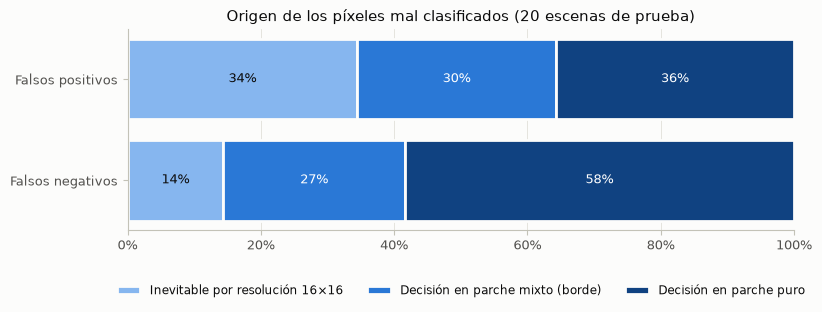

In [17]:
dec_rows, orc = [], []
mats['oraculo_parche'] = []
for i, (grid, (_, y)) in enumerate(zip(grids, prepared['test'])):
    b = to_grid(y); n0 = (b == 0).sum(-1); n1 = (b == 1).sum(-1)
    og = (n1 > n0).astype(np.int64)
    pure = (n0 == 0) | (n1 == 0); agree = grid == og
    fp_b, fn_b = np.where(grid == 1, n0, 0), np.where(grid == 0, n1, 0)
    for err, blk in [('FP', fp_b), ('FN', fn_b)]:
        dec_rows.append({'i': i, 'tipo': err, 'Inevitable por resolución 16×16': int(blk[agree].sum()),
                         'Decisión en parche mixto (borde)': int(blk[~agree & ~pure].sum()),
                         'Decisión en parche puro': int(blk[~agree & pure].sum())})
    mat = confusion(y, up(og), CLASSES); mats['oraculo_parche'].append(mat); m1 = metrics(mat, CLASSES)[1]
    orc.append({'i': i, 'escena': ids['test'][i], 'metodo': 'oraculo_parche', 'vp': int(mat[1, 1]), 'fp': int(mat[0, 1]),
                'fn': int(mat[1, 0]), 'vn': int(mat[0, 0]), 'soporte_1': m1['support'], 'iou': m1['iou'], 'f1': m1['f1'],
                'precision': m1['precision'], 'recall': m1['recall']})
orc = pd.DataFrame(orc)
dec_scene = pd.DataFrame(dec_rows)
dec = dec_scene.groupby('tipo').sum().drop(columns='i')
dec['total'] = dec.sum(axis=1)
display(dec)
dec_cases = dec_scene[dec_scene.i.isin([i for _, i in casos])].copy()
dec_cases.insert(0, 'escena', [ids['test'][i] for i in dec_cases.i])
print('Mismo desglose para las escenas de los casos representativos (sección 7):')
display(dec_cases.drop(columns='i').set_index(['escena', 'tipo']))
share = dec.drop(columns='total').div(dec.total, axis=0)
display((100 * share).round(1).astype(str) + ' %')
both = dec.drop(columns='total').sum()
print(f"Del total de píxeles mal clasificados ({int(dec.total.sum()):,}), "
      f"{100 * both.iloc[0] / dec.total.sum():.1f} % son inevitables con parches de 16×16 y "
      f"{100 * (both.iloc[0] + both.iloc[1]) / dec.total.sum():.1f} % están en parches de borde (mixtos).")
techo = pd.DataFrame({'Prithvi + RF': [m.iou.mean(), m.f1.mean()], 'Oráculo de parche (techo)': [orc.iou.mean(), orc.f1.mean()]},
                     index=['IoU media escena', 'F1 media escena'])
display(techo.round(3))

fig, ax = plt.subplots(figsize=(8.6, 2.6))
left = np.zeros(2)
labels_dec = list(share.columns)
for k, col in enumerate(labels_dec):
    vals = share.loc[['FN', 'FP'], col].values
    ax.barh(['Falsos negativos', 'Falsos positivos'], vals, left=left, color=C['seq'][k], edgecolor=C['surface'], linewidth=2, label=col)
    for j, (l, v) in enumerate(zip(left, vals)):
        if v > 0.07:
            ax.text(l + v / 2, j, f'{v:.0%}', ha='center', va='center', fontsize=9, color=C['ink'] if k == 0 else '#ffffff')
    left += vals
ax.set_xlim(0, 1); ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}')); ax.xaxis.grid(True)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.22), ncol=3, fontsize=8.5)
ax.set_title(f'Origen de los píxeles mal clasificados ({len(ids["test"])} escenas de prueba)')
fig.savefig(FIG / '07_origen_errores.png'); plt.show()

Errores a ≤ 8 px (240 m) del borde: FN 37% · FP 60%


pixeles         errores          tasa       
clase       0       1       0      1      0      1
rango                                             
1        9207    9160    2673   6185  0.290  0.675
2        8878    8753    2228   5521  0.251  0.631
3–4     18628   17596    3593   9943  0.193  0.565
5–8     36243   29948    3896  13208  0.107  0.441
9–16    69937   40914    1765  11782  0.025  0.288
17–32  147424   37487    1676  10302  0.011  0.275
>32    448508  120163    4945  37227  0.011  0.310

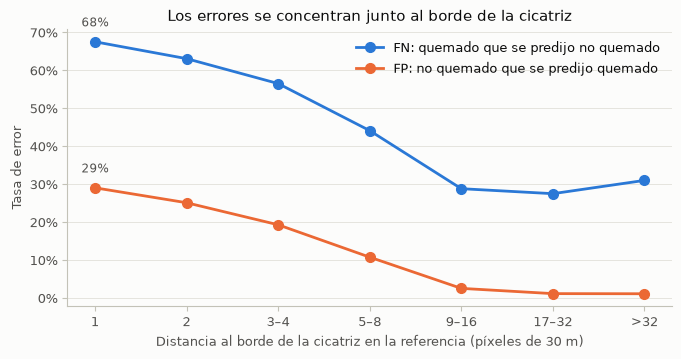

In [18]:
# Tasa de error según la distancia (en píxeles de 30 m) al borde más cercano de la referencia
bins = [0, 1, 2, 4, 8, 16, 32, np.inf]
bin_labels = ['1', '2', '3–4', '5–8', '9–16', '17–32', '>32']
parts = []
for i, (grid, (_, y)) in enumerate(zip(grids, prepared['test'])):
    pred = up(grid)
    d_to0 = ndimage.distance_transform_edt(y != 0) if (y == 0).any() else np.full(y.shape, np.inf)
    d_to1 = ndimage.distance_transform_edt(y != 1) if (y == 1).any() else np.full(y.shape, np.inf)
    bm, um = y == 1, y == 0
    parts.append(pd.DataFrame({'clase': 1, 'dist': d_to0[bm], 'error': pred[bm] == 0}))
    parts.append(pd.DataFrame({'clase': 0, 'dist': d_to1[um], 'error': pred[um] == 1}))
dd = pd.concat(parts, ignore_index=True)
dd['rango'] = pd.cut(dd.dist, bins=bins, labels=bin_labels)
rate = dd.groupby(['clase', 'rango'], observed=False).agg(pixeles=('error', 'size'), errores=('error', 'sum'))
rate['tasa'] = rate.errores / rate.pixeles
near = dd[dd.error].assign(cerca=lambda t: t.dist <= 8).groupby('clase').cerca.mean()
print(f'Errores a ≤ 8 px (240 m) del borde: FN {near.get(1, np.nan):.0%} · FP {near.get(0, np.nan):.0%}')
display(rate.unstack(0).round(3))

fig, ax = plt.subplots(figsize=(7.8, 3.6))
for cls, lab, color in [(1, 'FN: quemado que se predijo no quemado', C['FN']), (0, 'FP: no quemado que se predijo quemado', C['FP'])]:
    r = rate.loc[cls]
    ax.plot(range(len(bin_labels)), r.tasa.values, color=color, lw=2, marker='o', ms=7, label=lab)
    ax.annotate(f'{r.tasa.values[0]:.0%}', (0, r.tasa.values[0]), xytext=(0, 9), textcoords='offset points', fontsize=8.5,
                color=C['ink2'], ha='center', va='bottom')
ax.set_xticks(range(len(bin_labels))); ax.set_xticklabels(bin_labels); ax.yaxis.grid(True)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
ax.set_xlabel('Distancia al borde de la cicatriz en la referencia (píxeles de 30 m)'); ax.set_ylabel('Tasa de error')
ax.set_title('Los errores se concentran junto al borde de la cicatriz'); ax.legend(loc='upper right')
fig.savefig(FIG / '08_error_vs_distancia_borde.png'); plt.show()

In [19]:
# Fragmentos pequeños: componentes conexas (8-vecindad) de la clase quemada en la referencia
crows = []
for i, (grid, (_, y)) in enumerate(zip(grids, prepared['test'])):
    lab, n = ndimage.label(y == 1, structure=np.ones((3, 3), int))
    if n == 0:
        continue
    pred = up(grid); idx = np.arange(1, n + 1)
    size = ndimage.sum_labels(np.ones_like(lab), lab, idx); hit = ndimage.sum_labels(pred == 1, lab, idx)
    crows += [{'i': i, 'tam_px': int(s), 'detectado_px': int(h)} for s, h in zip(size, hit)]
comp = pd.DataFrame(crows)
comp['rango'] = pd.cut(comp.tam_px, [0, 16, 64, 256, 1024, np.inf], right=False,
                       labels=['<16 px (<1.4 ha)', '16–63 px (1.4–5.7 ha)', '64–255 px (5.8–23 ha)', '256–1023 px (23–92 ha)', '≥1024 px (≥92 ha)'])
frag = comp.groupby('rango', observed=False).agg(componentes=('tam_px', 'size'), pixeles=('tam_px', 'sum'),
                                                 detectados=('detectado_px', 'sum'),
                                                 con_alguna_deteccion=('detectado_px', lambda s: (s > 0).mean()))
frag['recall (píxeles)'] = frag.detectados / frag.pixeles
display(frag.round(3))
print('1 parche de 16×16 = 256 píxeles = 23 ha. Píxel = 30 m × 30 m = 0.09 ha.')

,componentes,pixeles,detectados,con_alguna_deteccion,recall (píxeles)
rango,,,,,
<16 px (<1.4 ha),8,17,1,0.125,0.059
16–63 px (1.4–5.7 ha),0,0,0,NaN,NaN
64–255 px (5.8–23 ha),0,0,0,NaN,NaN
256–1023 px (23–92 ha),1,532,502,1.000,0.944
≥1024 px (≥92 ha),20,263472,169350,0.900,0.643


1 parche de 16×16 = 256 píxeles = 23 ha. Píxel = 30 m × 30 m = 0.09 ha.


- **Predominan los falsos negativos:** hay 94 168 FN frente a 20 776 FP, así que el 82 % de los errores son FN. El modelo es conservador: precisión 0.75 > recall 0.60.
- **Resolución:** incluso un clasificador perfecto por parche (el oráculo) llegaría como máximo a IoU 0.806 y F1 0.890. El 18 % de los errores es inevitable con parches de 16×16 y el 46 % está en parches de borde. En los FP el efecto es más fuerte: el 60 % está a ≤ 8 píxeles (240 m) del borde, y la tasa de FP baja del 29 % junto al borde al 1 % a más de 16 píxeles.
- **Decisión:** el 58 % de los FN son parches enteros de cicatriz sin detectar, concentrados en pocas escenas (T11SLB, T15TVN.2019140, T17SNU, T16REV y T16SDC). Por eso la tasa de FN no baja de ~28 % ni siquiera lejos del borde. Esos errores no se explican por el borde, sino por lo que muestra la imagen (sección 10.1).
- **Fragmentos pequeños:** la referencia casi no tiene cicatrices pequeñas. Solo hay 8 componentes de menos de 16 píxeles (17 píxeles en total, de los que se detectó 1), mientras que 20 componentes de ≥ 92 ha concentran el 99.8 % de lo quemado. Esto refleja el origen de las etiquetas (perímetros de incendios grandes) y el diseño del método, en el que un parche equivale a 23 ha. **Con estos datos no se puede evaluar la detección de fragmentos pequeños**, y por diseño el método no puede delinearlos.

## 9. Firmas espectrales de aciertos y errores
Se comparan, **por parche puro** (todos sus píxeles válidos de una sola clase y ≥ 50 % válidos), índices calculados con la reflectancia original: NBR = (NIR − SWIR2)/(NIR + SWIR2), NDVI = (NIR − rojo)/(NIR + rojo), la reflectancia NIR y el brillo visible. Sirve para estudiar los errores que pide la ficha: superficies oscuras y sombras (NIR y brillo bajos), suelo descubierto (NDVI bajo con SWIR alto) y confusión con otros cambios de vegetación.

,parches,escenas,NBR,NDVI,NBR2,NIR (B8A),SWIR2,Brillo visible
cat,,,,,,,,
VP,512,17,-0.246,0.169,-0.005,0.117,0.189,0.063
FN,216,11,0.209,0.470,0.186,0.190,0.114,0.051
FP,29,8,-0.020,0.224,0.107,0.178,0.174,0.082
VN,2527,18,0.133,0.361,0.206,0.209,0.158,0.075


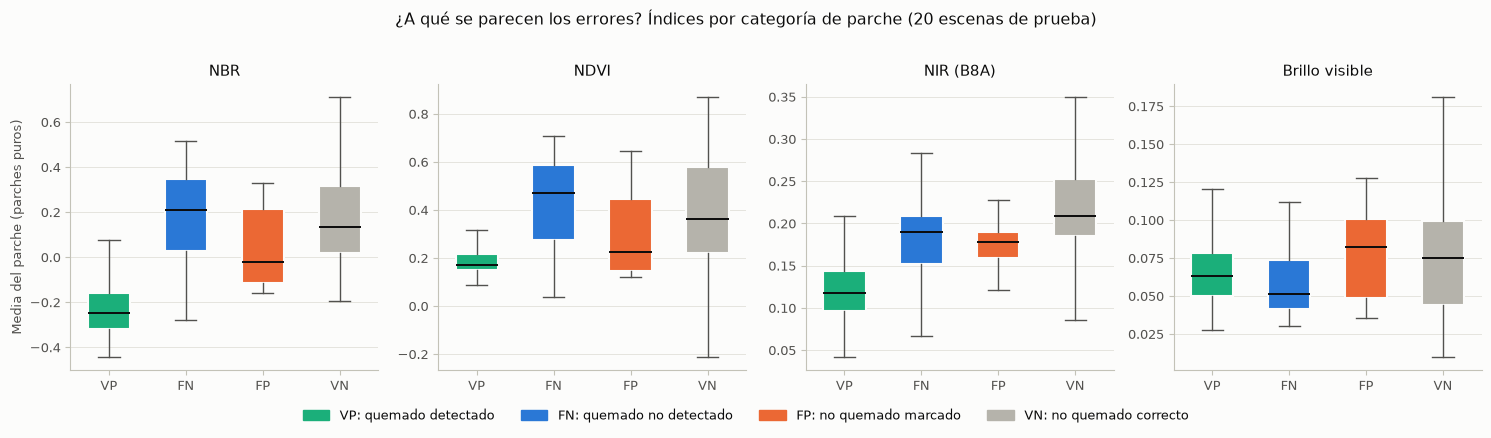

In [20]:
srows = []
for i, (grid, (x, y)) in enumerate(zip(grids, samples['test'])):
    pl = patch_labels(y)
    b = to_grid(y); pure = ((b == 0).sum(-1) == 0) | ((b == 1).sum(-1) == 0)
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', RuntimeWarning)
        means = {k: np.nanmean(to_grid(np.where(y >= 0, v, np.nan)), axis=-1) for k, v in indices(x).items()}
    for r_ in range(14):
        for c_ in range(14):
            if pl[r_, c_] < 0 or not pure[r_, c_]:
                continue
            cat = {(1, 1): 'VP', (1, 0): 'FN', (0, 1): 'FP', (0, 0): 'VN'}[(int(pl[r_, c_]), int(grid[r_, c_]))]
            srows.append({'i': i, 'escena': ids['test'][i], 'cat': cat, **{k: float(v[r_, c_]) for k, v in means.items()}})
spec = pd.DataFrame(srows)
order = ['VP', 'FN', 'FP', 'VN']
names = {'VP': 'VP: quemado detectado', 'FN': 'FN: quemado no detectado', 'FP': 'FP: no quemado marcado', 'VN': 'VN: no quemado correcto'}
resumen_spec = spec.groupby('cat')[['NBR', 'NDVI', 'NBR2', 'NIR (B8A)', 'SWIR2', 'Brillo visible']].median().loc[order]
resumen_spec.insert(0, 'parches', spec.groupby('cat').size().loc[order])
resumen_spec.insert(1, 'escenas', spec.groupby('cat').escena.nunique().loc[order])
display(resumen_spec.round(3))

fig, axes = plt.subplots(1, 4, figsize=(15, 3.9))
for ax, k in zip(axes, ['NBR', 'NDVI', 'NIR (B8A)', 'Brillo visible']):
    data = [spec.loc[spec.cat == c, k].values for c in order]
    bp = ax.boxplot(data, patch_artist=True, widths=0.55, showfliers=False, medianprops={'color': C['ink'], 'lw': 1.4},
                    whiskerprops={'color': C['ink2'], 'lw': 1}, capprops={'color': C['ink2'], 'lw': 1})
    for patch_, c in zip(bp['boxes'], order):
        patch_.set_facecolor(C[c]); patch_.set_edgecolor(C['surface']); patch_.set_linewidth(1.5)
    ax.set_xticks(range(1, 5)); ax.set_xticklabels(order); ax.yaxis.grid(True); ax.set_title(k)
axes[0].set_ylabel('Media del parche (parches puros)')
fig.legend(handles=[Patch(color=C[c], label=names[c]) for c in order], loc='lower center', ncol=4, bbox_to_anchor=(0.5, -0.07))
fig.suptitle(f'¿A qué se parecen los errores? Índices por categoría de parche ({len(ids["test"])} escenas de prueba)', y=1.02)
fig.tight_layout(); fig.savefig(FIG / '09_firmas_espectrales.png'); plt.show()

In [21]:
# Comparación DENTRO de cada escena. Mezclar escenas puede engañar porque cada una tiene su propio nivel de brillo;
# aquí cada error se compara con los aciertos de su misma escena (diferencia de medianas por píxel).
dentro = []
for i, (grid, (x, y)) in enumerate(zip(grids, samples['test'])):
    pred = up(grid); ix = indices(x)
    fp, vn, fn, vp = (y == 0) & (pred == 1), (y == 0) & (pred == 0), (y == 1) & (pred == 0), (y == 1) & (pred == 1)
    row = {'escena': ids['test'][i], 'px FP': int(fp.sum()), 'px FN': int(fn.sum())}
    for k in ['Brillo visible', 'NIR (B8A)', 'NBR', 'NDVI']:
        if fp.sum() >= 256 and vn.sum() >= 256:      # al menos un parche de cada categoría
            row[f'{k}: FP − VN'] = np.nanmedian(ix[k][fp]) - np.nanmedian(ix[k][vn])
        if fn.sum() >= 256 and vp.sum() >= 256:
            row[f'{k}: FN − VP'] = np.nanmedian(ix[k][fn]) - np.nanmedian(ix[k][vp])
    dentro.append(row)
dentro = pd.DataFrame(dentro)
fpd = dentro.dropna(subset=['NIR (B8A): FP − VN']) if 'NIR (B8A): FP − VN' in dentro else dentro.iloc[:0]
fnd = dentro.dropna(subset=['NBR: FN − VP']) if 'NBR: FN − VP' in dentro else dentro.iloc[:0]
conteo = lambda d, col, signo: int((d[col] * signo > 0).sum()) if col in d else 0
resumen_dentro = pd.DataFrame({
    'escenas comparadas': [len(fpd), len(fnd)],
    'más oscuro en el visible': [conteo(fpd, 'Brillo visible: FP − VN', -1), conteo(fnd, 'Brillo visible: FN − VP', -1)],
    'NIR menor': [conteo(fpd, 'NIR (B8A): FP − VN', -1), conteo(fnd, 'NIR (B8A): FN − VP', -1)],
    'NBR menor': [conteo(fpd, 'NBR: FP − VN', -1), conteo(fnd, 'NBR: FN − VP', -1)],
    'NBR mayor': [conteo(fpd, 'NBR: FP − VN', 1), conteo(fnd, 'NBR: FN − VP', 1)],
    'NDVI mayor': [conteo(fpd, 'NDVI: FP − VN', 1), conteo(fnd, 'NDVI: FN − VP', 1)]},
    index=['FP frente al no quemado bien clasificado (VN)', 'FN frente al quemado detectado (VP)'])
print('Número de escenas en que el error es más oscuro / tiene NBR menor o mayor que los aciertos de su propia escena:')
display(resumen_dentro)
display(fpd[['escena', 'px FP'] + [c for c in fpd.columns if 'FP − VN' in c]].round(3))
display(fnd[['escena', 'px FN'] + [c for c in fnd.columns if 'FN − VP' in c]].round(3))

Número de escenas en que el error es más oscuro / tiene NBR menor o mayor que los aciertos de su propia escena:


,escenas comparadas,más oscuro en el visible,NIR menor,NBR menor,NBR mayor,NDVI mayor
FP frente al no quemado bien clasificado (VN),13,9,12,8,5,3
FN frente al quemado detectado (VP),15,3,0,0,15,14


,escena,px FP,Brillo visible: FP − VN,NIR (B8A): FP − VN,NBR: FP − VN,NDVI: FP − VN
1,T10TGL.2018215,3058,-0.017,-0.035,-0.008,-0.001
2,T11SLB.2018197,511,0.001,-0.056,-0.215,-0.165
4,T11TMF.2020217,4886,-0.006,-0.011,-0.015,-0.001
5,T11TPH.2020249,3175,-0.002,-0.015,0.006,-0.011
6,T11TQG.2018221,1247,-0.009,-0.012,0.024,0.034
8,T12SUJ.2019308,1964,-0.048,-0.113,0.011,-0.039
9,T12SXA.2020247,894,-0.009,-0.023,-0.041,-0.001
10,T12TVK.2020308,959,0.004,0.016,-0.022,-0.005
11,T14RNV.2018215,373,-0.002,-0.023,-0.063,-0.045
12,T14SKF.2019246,556,0.003,-0.018,-0.109,-0.093


,escena,px FN,Brillo visible: FN − VP,NIR (B8A): FN − VP,NBR: FN − VP,NDVI: FN − VP
0,T10TGK.2020285,1024,0.038,0.079,0.104,0.015
1,T10TGL.2018215,804,0.016,0.033,0.042,0.012
2,T11SLB.2018197,33690,-0.005,0.079,0.444,0.294
3,T11SMU.2020299,19836,0.005,0.027,0.143,0.059
6,T11TQG.2018221,597,0.006,0.027,0.147,0.031
7,T12RVV.2020320,2773,0.004,0.005,0.026,-0.000
8,T12SUJ.2019308,1792,0.016,0.027,0.040,0.000
9,T12SXA.2020247,4000,0.005,0.014,0.033,0.008
10,T12TVK.2020308,2222,0.007,0.038,0.174,0.047
11,T14RNV.2018215,1079,0.017,0.063,0.157,0.027


Medianas por parche puro en las 20 escenas de prueba (VP: 512 parches, FN: 216, FP: 29, VN: 2 527):

| Categoría | NBR | NDVI | NIR (B8A) | SWIR2 | Brillo visible |
|---|---|---|---|---|---|
| VP: quemado detectado | −0.25 | 0.17 | 0.12 | 0.19 | 0.063 |
| FN: quemado no detectado | +0.21 | 0.47 | 0.19 | 0.11 | 0.051 |
| FP: no quemado marcado | −0.02 | 0.22 | 0.18 | 0.17 | 0.082 |
| VN: no quemado correcto | +0.13 | 0.36 | 0.21 | 0.16 | 0.075 |

- **Lo detectado tiene la firma clásica del quemado:** NIR bajo, porque se perdió la vegetación, y SWIR2 alto, porque quedan suelo y ceniza secos. Juntos dan un NBR negativo (−0.25, frente a +0.13 del fondo). Por eso **NIR y SWIR son la información clave** (pregunta 2 de la ficha): el NBR combina justamente esas dos bandas.
- **Cuidado al leer esta tabla:** junta parches de escenas con niveles de brillo muy distintos. Por eso la comparación válida es **dentro de cada escena** (tabla siguiente).

**Comparación dentro de cada escena** (diferencia de medianas entre los errores y los aciertos de la misma escena; solo escenas con al menos un parche de cada categoría):
- **Falsos positivos (13 escenas):** tienen NIR menor que el fondo bien clasificado en 12 escenas y brillo visible menor en 9, pero NBR menor solo en 8. **El modelo confunde con cicatriz zonas más oscuras que su entorno** (sombras de ladera, vegetación rala o suelo oscuro) aunque su NBR no sea de quemado. El caso más claro es T10TGL.2018215: las laderas marcadas son más oscuras (brillo −0.017, NIR −0.035), con un NBR casi igual al del fondo (−0.008). Esa es la firma típica de una sombra, que oscurece todas las bandas a la vez.
- **Falsos negativos (15 escenas):** tienen NBR mayor que lo quemado detectado en las 15 escenas y NDVI mayor en 14. **Lo que el modelo deja sin marcar es siempre la parte más verde del perímetro:** zonas de baja severidad, islas sin quemar dentro del perímetro, rebrote o áreas que todavía no se habían quemado en la fecha de la imagen.
- **¿Por qué una región oscura no basta como evidencia de incendio?** (pregunta 1 de la ficha). Porque las sombras y la vegetación rala también son oscuras en el visible y en el NIR, y el modelo las confunde con cicatriz. Distinguirlas exige el SWIR (el NBR de una sombra no baja) y, mejor aún, una imagen de antes del incendio. El agua, las coníferas densas y los suelos húmedos también son oscuros.

## 10. Control: la misma cabeza con solo bandas espectrales
Extensión opcional sugerida en la celda 24. Se cambia **únicamente** la representación de cada parche: en vez de los 768 valores del embedding de Prithvi se usan 15 rasgos espectrales simples (media y desviación de las 6 bandas normalizadas + media de NBR, NDVI y NBR2). Mismas escenas, mismas etiquetas por parche, mismo Random Forest con los mismos hiperparámetros, misma evaluación. Responde a la pregunta del curso: *¿qué aporta el modelo fundacional frente a la información espectral directa?*

,escenas,escenas con IoU definido,IoU media escena,IoU IC95,F1 media escena,F1 IC95,Precisión media escena,Precisión IC95,Recall media escena,Recall IC95,IoU agregado píxel,F1 agregado píxel,Precisión agregado píxel,Recall agregado píxel
método,,,,,,,,,,,,,,
linea_base,20,20,0.000,0.000–0.000,0.000,0.000–0.000,0.000,0.000–0.000,0.000,0.000–0.000,0.000,0.000,0.000,0.000
control_espectral,20,20,0.543,0.418–0.660,0.654,0.525–0.771,0.751,0.618–0.863,0.646,0.500–0.780,0.608,0.756,0.847,0.683
prithvi_rf,20,20,0.524,0.397–0.643,0.633,0.494–0.757,0.746,0.601–0.874,0.604,0.455–0.743,0.596,0.747,0.891,0.643
oraculo_parche,20,20,0.806,0.768–0.847,0.890,0.867–0.914,0.896,0.877–0.918,0.884,0.855–0.914,0.886,0.940,0.940,0.939


,diferencia media,IC95,escenas donde Prithvi gana
IoU,-0.01892,-0.062 a +0.029,7/20
F1,-0.021042,-0.065 a +0.026,7/20


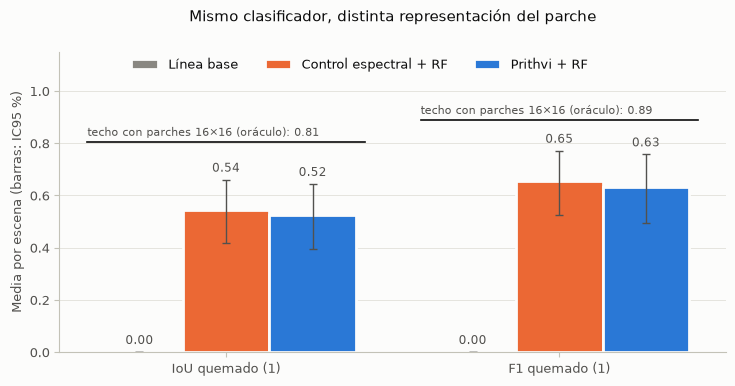

In [22]:
def spectral_features(x_norm, x_raw):
    g = to_grid(x_norm[:, 0])                                   # (6, 14, 14, 256)
    feats = [g.mean(-1), g.std(-1)]
    ix = indices(x_raw)
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', RuntimeWarning)
        for k in ['NBR', 'NDVI', 'NBR2']:
            feats.append(np.nan_to_num(np.nanmean(to_grid(ix[k]), axis=-1))[None])
    return np.concatenate(feats, axis=0).transpose(1, 2, 0)    # (14, 14, 15)

S = {split: [spectral_features(xn, xr) for (xn, _), (xr, _) in zip(prepared[split], samples[split])] for split in ['train', 'test']}
head_spec, _, _ = train_head(S['train'], prepared['train'])
grids_spec = [predict_grid(head_spec, s) for s in S['test']]
per_spec, mats_spec = evaluate(grids_spec, prepared['test'], majority, 'control_espectral')
mats['control_espectral'] = mats_spec['control_espectral']

todo = pd.concat([per_scene, per_spec[per_spec.metodo == 'control_espectral'], orc], ignore_index=True)
comp_tabla = summarize(todo, mats).loc[['linea_base', 'control_espectral', 'prithvi_rf', 'oraculo_parche']]
display(comp_tabla.round(3))

def paired_diff(a, b, B=10000, seed=0):
    d = np.asarray(a, float) - np.asarray(b, float); d = d[np.isfinite(d)]
    idx = np.random.default_rng(seed).integers(0, len(d), size=(B, len(d)))
    lo, hi = np.percentile(d[idx].mean(1), [2.5, 97.5])
    return {'diferencia media': d.mean(), 'IC95': f'{lo:+.3f} a {hi:+.3f}', 'escenas donde Prithvi gana': f'{(d > 0).sum()}/{len(d)}'}
pp = per_scene[per_scene.metodo == 'prithvi_rf'].set_index('i'); ps = per_spec[per_spec.metodo == 'control_espectral'].set_index('i')
display(pd.DataFrame({k: paired_diff(pp[k], ps[k]) for k in ['iou', 'f1']}).T.rename(index={'iou': 'IoU', 'f1': 'F1'}))

fig, ax = plt.subplots(figsize=(8.6, 3.9))
meths = [('linea_base', 'Línea base', C['base']), ('control_espectral', 'Control espectral + RF', C['espectral']), ('prithvi_rf', 'Prithvi + RF', C['modelo'])]
w = 0.26
for k, (name, label, color) in enumerate(meths):
    d = todo[todo.metodo == name]
    means = np.array([d.iou.mean(), d.f1.mean()]); cis = np.array([boot_ci(d.iou), boot_ci(d.f1)])
    xs = np.arange(2) + (k - 1) * w
    ax.bar(xs, means, width=w, color=color, label=label, edgecolor=C['surface'], linewidth=2)
    ax.errorbar(xs, means, yerr=[means - cis[:, 0], cis[:, 1] - means], fmt='none', ecolor=C['ink2'], elinewidth=1, capsize=3)
    for xv, m_, hi in zip(xs, means, cis[:, 1]):
        ax.text(xv, max(hi, m_) + 0.02, f'{m_:.2f}', ha='center', va='bottom', fontsize=8.5, color=C['ink2'])
o_ = todo[todo.metodo == 'oraculo_parche']
for j, val in enumerate([o_.iou.mean(), o_.f1.mean()]):
    ax.plot([j - 1.6 * w, j + 1.6 * w], [val, val], color=C['ink'], lw=1.2)
    ax.text(j - 1.6 * w, val + 0.012, f'techo con parches 16×16 (oráculo): {val:.2f}', va='bottom', ha='left', fontsize=8, color=C['ink2'])
ax.set_xticks([0, 1]); ax.set_xticklabels(['IoU quemado (1)', 'F1 quemado (1)']); ax.set_xlim(-0.5, 1.5)
ax.set_ylim(0, 1.15); ax.yaxis.grid(True); ax.set_ylabel('Media por escena (barras: IC95 %)')
ax.legend(loc='upper center', ncol=3, bbox_to_anchor=(0.45, 1.02)); ax.set_title('Mismo clasificador, distinta representación del parche', pad=22)
fig.savefig(FIG / '10_control_espectral.png'); plt.show()

- Con la misma cabeza, 15 rasgos espectrales simples obtienen IoU 0.543 y F1 0.654; Prithvi obtiene 0.524 y 0.633. La diferencia pareada (Prithvi − control) es −0.019 en IoU (IC95 −0.062 a +0.029) y −0.021 en F1 (−0.065 a +0.026), y Prithvi gana en 7 de las 20 escenas. **No hay evidencia de que los embeddings de Prithvi congelado superen a la información espectral directa en esta configuración**, aunque tampoco de que sean peores.
- Esto es coherente con la física del problema: la cicatriz tiene una firma espectral fuerte (el NBR) que un clasificador sencillo aprovecha sin necesitar contexto espacial aprendido.
- **Límites de la comparación:** el encoder está congelado y sin *fine-tuning*; se usa una sola fecha, aunque Prithvi-EO-1.0 se preentrenó con 3; la normalización es propia y no la del preentrenamiento; la salida es por parche de 480 m; y solo hay 20 escenas de entrenamiento. Como referencia no comparable, el modelo oficial ajustado a este dataset (*fine-tuning* completo con decoder de segmentación, todas las escenas, resolución de píxel) reporta **IoU 0.73** en la clase quemada [3].

### 10.1 ¿Por qué fallan los dos métodos en las mismas escenas? Visibilidad espectral de la cicatriz
Se mide, en cada escena 512×512 completa, el NBR mediano dentro del área quemada según la referencia y su contraste con el área no quemada. Si el área "quemada" tiene NBR positivo (todavía hay vegetación verde) o no se distingue de su entorno, **ningún clasificador que solo vea esta imagen** puede separarla bien: el problema está en los datos (rebrote, quema bajo dosel verde, desfase entre la fecha de la imagen y el perímetro, o error de etiqueta) y no solo en el modelo. Es un análisis exploratorio que usa etiquetas de prueba; no se usa para ajustar nada.

,variable,F1 de,Spearman ρ,p
0,NBR mediana quemado,F1 Prithvi,-0.7364,0.0002
1,NBR mediana quemado,F1 control espectral,-0.7504,0.0001
2,contraste NBR,F1 Prithvi,0.6258,0.0032
3,contraste NBR,F1 control espectral,0.4677,0.0376
4,% del área quemada con NBR < 0,F1 Prithvi,0.5335,0.0154
5,% del área quemada con NBR < 0,F1 control espectral,0.6070,0.0045


,escena,región,fecha,área quemada etiquetada en la escena (km²),NBR mediana quemado,NBR mediana no quemado,contraste NBR,% del área quemada con NBR < 0,F1 Prithvi,F1 control espectral
4,T11TMF.2020217,Oeste,2020-08-04,4.762,-0.318,-0.126,0.192,100.000,0.667,0.424
0,T10TGK.2020285,Oeste,2020-10-11,161.871,-0.295,-0.055,0.241,94.490,0.990,0.995
6,T11TQG.2018221,Oeste,2018-08-09,7.709,-0.289,0.028,0.317,95.937,0.896,0.886
10,T12TVK.2020308,Oeste,2020-11-03,13.578,-0.270,0.163,0.433,91.927,0.890,0.864
11,T14RNV.2018215,Centro-Este,2018-08-03,5.935,-0.268,0.047,0.315,89.081,0.884,0.861
5,T11TPH.2020249,Oeste,2020-09-05,5.873,-0.251,-0.105,0.146,100.000,0.787,0.799
8,T12SUJ.2019308,Oeste,2019-11-04,13.448,-0.214,0.009,0.223,95.235,0.863,0.875
7,T12RVV.2020320,Oeste,2020-11-15,5.558,-0.199,-0.077,0.122,99.838,0.697,0.814
1,T10TGL.2018215,Oeste,2018-08-03,8.570,-0.181,0.141,0.322,91.084,0.819,0.862
12,T14SKF.2019246,Centro-Este,2019-09-03,4.810,-0.180,0.028,0.208,96.427,0.678,0.777


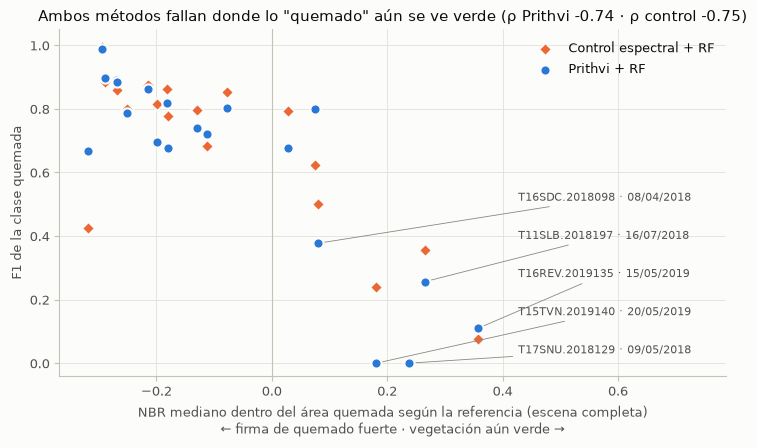

Distancia entre el centro de la escena y las coordenadas publicadas del Lions Fire: 4.5 km
Área etiquetada como quemada en la escena 512×512: 57.7 km² | tamaño final del Lions Fire: 54.0 km²
Área etiquetada con NBR < 0 el 16/07/2018: 18 % | fracción del tamaño final ya quemada: 30 % (5 jul) a 38 % (31 jul)


In [23]:
# ¿Se distingue la cicatriz en la imagen? NBR del área quemada según la referencia y su contraste con lo no quemado,
# medidos en la escena 512×512 completa (más píxeles de fondo que el recorte). Solo análisis: usa etiquetas de prueba.
from scipy.stats import spearmanr
vis = []
for i, (im, lab) in enumerate(pairs['test']):
    with rasterio.open(im) as f:
        arr = f.read(masked=True).astype(np.float32).filled(np.nan)
    with rasterio.open(lab) as f:
        yy = f.read(1, masked=True).astype(np.int64).filled(-1)
    with np.errstate(invalid='ignore', divide='ignore'):
        nbr = (arr[3] - arr[5]) / (arr[3] + arr[5])
    nb_q, nb_nq = nbr[(yy == 1) & np.isfinite(nbr)], nbr[(yy == 0) & np.isfinite(nbr)]
    vis.append({'i': i, 'escena': ids['test'][i], 'región': region(ids['test'][i]), 'fecha': doy_to_date(ids['test'][i][7:]),
                'área quemada etiquetada en la escena (km²)': (yy == 1).sum() * 0.0009,
                'NBR mediana quemado': np.median(nb_q), 'NBR mediana no quemado': np.median(nb_nq),
                'contraste NBR': np.median(nb_nq) - np.median(nb_q), '% del área quemada con NBR < 0': 100 * (nb_q < 0).mean()})
vis = pd.DataFrame(vis)
vis['F1 Prithvi'] = m.set_index('i').loc[vis.i, 'f1'].values
vis['F1 control espectral'] = ps.loc[vis.i, 'f1'].values
corr = pd.DataFrame([{'variable': col, 'F1 de': f1c, 'Spearman ρ': spearmanr(vis[col], vis[f1c])[0], 'p': spearmanr(vis[col], vis[f1c])[1]}
                     for col in ['NBR mediana quemado', 'contraste NBR', '% del área quemada con NBR < 0']
                     for f1c in ['F1 Prithvi', 'F1 control espectral']])
display(corr.round(4))
display(vis.drop(columns='i').sort_values('NBR mediana quemado').round(3))

rho_p, rho_c = corr[corr.variable == 'NBR mediana quemado']['Spearman ρ'].values
fig, ax = plt.subplots(figsize=(8.6, 4.5))
ax.scatter(vis['NBR mediana quemado'], vis['F1 control espectral'], marker='D', s=40, color=C['espectral'], edgecolor=C['surface'],
           linewidth=1.2, label='Control espectral + RF', zorder=3)
ax.scatter(vis['NBR mediana quemado'], vis['F1 Prithvi'], marker='o', s=54, color=C['modelo'], edgecolor=C['surface'],
           linewidth=1.5, label='Prithvi + RF', zorder=4)
low = vis[vis['F1 Prithvi'] < 0.4].sort_values(['F1 Prithvi', 'NBR mediana quemado'], ascending=[False, True])
x_text = vis['NBR mediana quemado'].max() + 0.07
for k, (_, r) in enumerate(low.iterrows()):
    ax.annotate(f"{r.escena} · {r.fecha:%d/%m/%Y}", xy=(r['NBR mediana quemado'], r['F1 Prithvi']), xytext=(x_text, 0.52 - 0.12 * k),
                textcoords='data', ha='left', va='center', fontsize=8, color=C['ink2'],
                arrowprops={'arrowstyle': '-', 'color': C['muted'], 'lw': 0.6})
ax.axvline(0, color=C['axis'], lw=0.8)
ax.set_xlim(vis['NBR mediana quemado'].min() - 0.05, x_text + 0.36); ax.set_ylim(-0.04, 1.05); ax.grid(True)
ax.set_xlabel('NBR mediano dentro del área quemada según la referencia (escena completa)\n← firma de quemado fuerte · vegetación aún verde →')
ax.set_ylabel('F1 de la clase quemada'); ax.legend(loc='upper right')
ax.set_title(f'Ambos métodos fallan donde lo "quemado" aún se ve verde (ρ Prithvi {rho_p:.2f} · ρ control {rho_c:.2f})')
fig.savefig(FIG / '10b_visibilidad_cicatriz.png'); plt.show()

# Caso T11SLB.2018197 frente a un incendio documentado (fuentes en el texto): Lions Fire, Ansel Adams Wilderness, 2018
LIONS = {'lat': 37.571, 'lon': -119.118, 'acres_final': 13347, 'acres_5_jul': 4000, 'acres_31_jul': 5095}
if 'T11SLB.2018197' in ids['test']:
    k = ids['test'].index('T11SLB.2018197')
    with rasterio.open(pairs['test'][k][0]) as f:
        b = f.bounds
        lon_c, lat_c = warp_transform(f.crs, 'EPSG:4326', [(b.left + b.right) / 2], [(b.bottom + b.top) / 2])
    v_ = vis[vis.escena == 'T11SLB.2018197'].iloc[0]
    print(f"Distancia entre el centro de la escena y las coordenadas publicadas del Lions Fire: "
          f"{haversine_km(lat_c[0], lon_c[0], LIONS['lat'], LIONS['lon']):.1f} km")
    print(f"Área etiquetada como quemada en la escena 512×512: {v_['área quemada etiquetada en la escena (km²)']:.1f} km² "
          f"| tamaño final del Lions Fire: {LIONS['acres_final'] * 0.00404686:.1f} km²")
    print(f"Área etiquetada con NBR < 0 el {v_.fecha:%d/%m/%Y}: {v_['% del área quemada con NBR < 0']:.0f} % | fracción del tamaño final "
          f"ya quemada: {100 * LIONS['acres_5_jul'] / LIONS['acres_final']:.0f} % (5 jul) a {100 * LIONS['acres_31_jul'] / LIONS['acres_final']:.0f} % (31 jul)")

- **El NBR del área quemada explica las fallas mejor que el método:** la correlación de Spearman entre el NBR mediano dentro del área etiquetada como quemada y el F1 por escena es **ρ = −0.74 (p = 0.0002) para Prithvi y ρ = −0.75 (p = 0.0001) para el control**. Las cinco escenas con F1 < 0.4 tienen NBR positivo dentro del perímetro (de 0.08 a 0.36), es decir, **vegetación todavía verde donde la etiqueta dice quemado**. De las 15 escenas con F1 ≥ 0.6, 13 tienen NBR negativo. Ambos métodos fallan en las mismas escenas.
- **T11SLB.2018197 y el Lions Fire:** la escena está a 4.5 km de las coordenadas publicadas del *Lions Fire* (Ansel Adams Wilderness, Sierra Nevada) [5]. Ese incendio empezó por un rayo el 11-jun-2018 y siguió creciendo: unos 4 000 acres el 5-jul, 5 095 el 31-jul y 13 347 al final (inactivo desde el 1-oct-2018) [5], [6]. El área etiquetada en la escena (**57.7 km²**) coincide con el tamaño final del incendio (**54.0 km²**), pero el 16-jul solo el **18 %** de esa área tenía firma de quemado (NBR < 0), cuando para esa fecha se había quemado entre el 30 y el 38 % del total. **Hipótesis bien sustentada:** la etiqueta es el perímetro final y la imagen es de mitad del incendio, así que el "error" del modelo es correcto para la fecha de la imagen. Habría que confirmarlo con la fecha y el perímetro oficiales (MTBS).
- **T17SNU.2018129, T16REV.2019135 y T16SDC.2018098** (Carolina del Sur y Alabama, abril–mayo) tienen NBR de 0.08 a 0.36 dentro del área quemada y un entorno muy verde (NBR de 0.27 a 0.65). Es plausible que sean **quemas de sotobosque o prescritas bajo dosel de pino**, frecuentes en esa región y época, que casi no cambian la reflectancia vista desde arriba. Además están en la región con menos escenas de entrenamiento. **T15TVN.2019140** (norte de Minnesota, 20-may) tiene un contraste casi nulo (0.07), compatible con un rebrote rápido de primavera.
- **Conclusión:** buena parte de los falsos negativos son **limitaciones de la etiqueta o de la fecha de la imagen**, no fallas que un mejor clasificador de esta sola imagen pudiera corregir. Esto responde la pregunta 3 de la ficha: **el tiempo transcurrido entre el incendio y la imagen importa**. Si la imagen se tomó antes de que el fuego terminara, o cuando la vegetación ya rebrotó, la cicatriz no se ve. Un par de imágenes antes y después del incendio (dNBR) reduciría esta ambigüedad.

## 11. Curva de aprendizaje: 4 → 10 → 20 escenas de entrenamiento
Responde la pregunta 6 de la celda 24 (*¿cuánto limita entrenar con cuatro escenas?*). Los subconjuntos de 4 y 10 escenas son los que entrega el mismo procedimiento de selección con `NTRAIN=4` y `NTRAIN=10` (4 es el valor por defecto de la plantilla) y están anidados dentro de las 20. Para cada tamaño se recalcula todo lo que depende de entrenamiento (normalización, embeddings, cabeza y clase de la línea base) y se evalúa en **las mismas 20 escenas de prueba**. La curva es descriptiva: no se usa para escoger configuración.

,ntrain,metodo,parches_entrenamiento,% parches quemados train,clase_linea_base,iou_media,iou_lo,iou_hi,f1_media,precision_media,recall_media,iou_agregado,f1_agregado
0,4,prithvi_rf,784,63.903,1,0.316,0.205,0.448,0.425,0.317,0.993,0.314,0.478
1,4,control_espectral,784,63.903,1,0.454,0.334,0.577,0.571,0.576,0.690,0.500,0.667
2,4,linea_base,784,63.903,1,0.264,0.151,0.402,0.358,0.264,1.000,0.263,0.417
3,10,prithvi_rf,1960,52.296,1,0.470,0.347,0.590,0.587,0.599,0.702,0.532,0.695
4,10,control_espectral,1960,52.296,1,0.483,0.365,0.601,0.603,0.618,0.705,0.560,0.718
5,10,linea_base,1960,52.296,1,0.264,0.151,0.402,0.358,0.264,1.000,0.263,0.417
6,20,prithvi_rf,3920,37.628,0,0.524,0.397,0.643,0.633,0.746,0.604,0.596,0.747
7,20,control_espectral,3920,37.628,0,0.543,0.418,0.660,0.654,0.751,0.646,0.608,0.756
8,20,linea_base,3920,37.628,0,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000


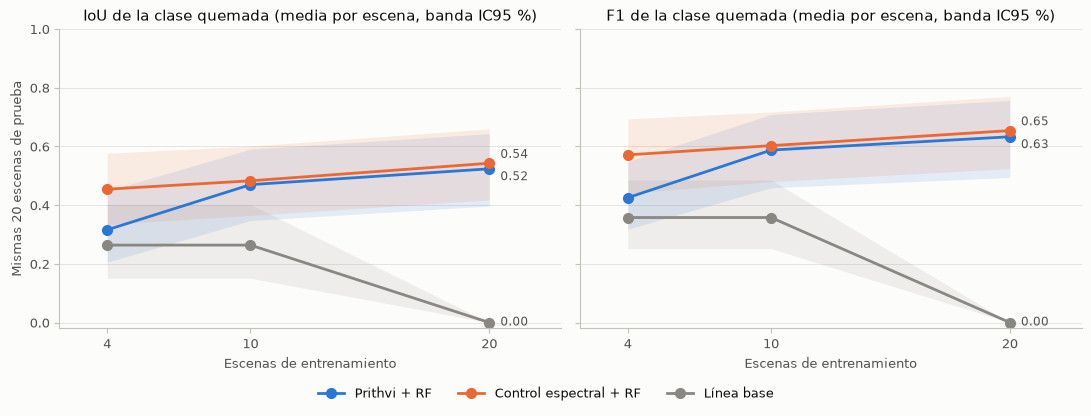

In [24]:
if 'CURVA_IDS' not in globals():   # notebook principal: subconjuntos que entrega el mismo procedimiento (verificados localmente)
    CURVA_IDS = {4: ['T12SUH.2020188', 'T12SVC.2019245', 'T12TUK.2020286', 'T13TCJ.2020200'],
                 10: ['T11TKE.2018215', 'T11TMF.2019312', 'T12SUH.2020188', 'T12SVC.2019245', 'T12SVD.2018168',
                      'T12TUK.2020286', 'T13TCJ.2020200', 'T15RTM.2020059', 'T16RFT.2019250', 'T17RMJ.2018064'],
                 20: list(COLAB_TRAIN)}
    CURVA_IDS[len(ids['train'])] = ids['train']
CURVA_IDS = {n: v for n, v in CURVA_IDS.items() if set(v) <= set(ids['train'])}   # solo tamaños disponibles
curve, curve_scene = [], []
t0 = time.perf_counter()
for n in sorted(CURVA_IDS):
    k = [ids['train'].index(s) for s in CURVA_IDS[n]]
    tr_raw = [samples['train'][j] for j in k]
    if n == len(ids['train']):
        prep_tr, prep_te, Ftr, Fte = [prepared['train'][j] for j in k], prepared['test'], [F['train'][j] for j in k], F['test']
    else:
        m_n, s_n = train_normalization(tr_raw)
        prep_tr = [(normalize(x, m_n, s_n), y) for x, y in tr_raw]
        prep_te = [(normalize(x, m_n, s_n), y) for x, y in samples['test']]
        Ftr, Fte = extract(prep_tr), extract(prep_te)
    maj_n, cnt_n = train_majority(tr_raw)
    h_n, _, Y_n = train_head(Ftr, prep_tr)
    d_p, mt_p = evaluate([predict_grid(h_n, f) for f in Fte], prep_te, maj_n, 'prithvi_rf')
    Str = [spectral_features(xn, xr) for (xn, _), (xr, _) in zip(prep_tr, tr_raw)]
    Ste = [spectral_features(xn, xr) for (xn, _), (xr, _) in zip(prep_te, samples['test'])]
    hs_n, _, _ = train_head(Str, prep_tr)
    d_s, mt_s = evaluate([predict_grid(hs_n, s) for s in Ste], prep_te, maj_n, 'control_espectral')
    allm = pd.concat([d_p, d_s[d_s.metodo == 'control_espectral']], ignore_index=True)
    allmats = {**mt_p, 'control_espectral': mt_s['control_espectral']}
    for name in ['prithvi_rf', 'control_espectral', 'linea_base']:
        d = allm[allm.metodo == name]; pooled = metrics(sum(allmats[name]), CLASSES)[1]
        row = {'ntrain': n, 'metodo': name, 'parches_entrenamiento': len(Y_n), '% parches quemados train': 100 * (Y_n == 1).mean(),
               'clase_linea_base': maj_n, 'iou_agregado': pooled['iou'], 'f1_agregado': pooled['f1']}
        for met in ['iou', 'f1', 'precision', 'recall']:
            lo, hi = boot_ci(d[met]); row.update({f'{met}_media': d[met].mean(), f'{met}_lo': lo, f'{met}_hi': hi})
        curve.append(row)
    curve_scene.append(allm.assign(ntrain=n))
TIMES['curva_aprendizaje_s'] = time.perf_counter() - t0
cv = pd.DataFrame(curve)
display(cv[['ntrain', 'metodo', 'parches_entrenamiento', '% parches quemados train', 'clase_linea_base', 'iou_media', 'iou_lo', 'iou_hi',
            'f1_media', 'precision_media', 'recall_media', 'iou_agregado', 'f1_agregado']].round(3))

SERIES = [('prithvi_rf', 'Prithvi + RF', C['modelo']), ('control_espectral', 'Control espectral + RF', C['espectral']),
          ('linea_base', 'Línea base', C['base'])]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.9), sharey=True)
for ax, met, lab in zip(axes, ['iou', 'f1'], ['IoU', 'F1']):
    ends = {name: cv[cv.metodo == name].iloc[-1][f'{met}_media'] for name, _, _ in SERIES}
    top = max(['prithvi_rf', 'control_espectral'], key=ends.get)
    for name, label, color in SERIES:
        d = cv[cv.metodo == name]
        ax.plot(d.ntrain, d[f'{met}_media'], color=color, lw=2, marker='o', ms=7, label=label)
        ax.fill_between(d.ntrain, d[f'{met}_lo'], d[f'{met}_hi'], color=color, alpha=0.12, lw=0)
        dy = 0 if name == 'linea_base' else (6 if name == top else -6)
        ax.annotate(f'{ends[name]:.2f}', (d.ntrain.iloc[-1], ends[name]), xytext=(8, dy),
                    textcoords='offset points', va='center', fontsize=8.5, color=C['ink2'])
    ax.set_xticks(sorted(CURVA_IDS)); ax.set_xlim(min(CURVA_IDS) - 2, max(CURVA_IDS) * 1.15); ax.set_ylim(-0.02, 1.0)
    ax.set_xlabel('Escenas de entrenamiento'); ax.set_title(f'{lab} de la clase quemada (media por escena, banda IC95 %)'); ax.yaxis.grid(True)
axes[0].set_ylabel(f'Mismas {len(ids["test"])} escenas de prueba')
fig.legend(*axes[0].get_legend_handles_labels(), loc='lower center', ncol=3, bbox_to_anchor=(0.5, -0.07))
fig.tight_layout(); fig.savefig(FIG / '11_curva_aprendizaje.png'); plt.show()

- **Con 4 escenas (la plantilla por defecto) el resultado no es confiable.** Esas 4 escenas tienen 64 % de parches quemados, así que hasta la clase de la línea base pasa a ser "quemado". Prithvi + RF marca casi todo como quemado (recall 0.99, precisión 0.32) y llega a IoU 0.32, apenas por encima de la línea base (0.26, prediciendo todo quemado).
- **Prithvi mejora con más datos:** con 4, 10 y 20 escenas, la IoU pasa de 0.32 a 0.47 y a 0.52, y el F1 de 0.43 a 0.59 y a 0.63. El control espectral empieza más alto (IoU 0.45) y sube menos (0.48 → 0.54): con pocos datos, 768 rasgos son más difíciles de aprovechar que 15.
- **La línea base depende del subconjunto:** es "quemado" con 4 y 10 escenas y "no quemado" con 20. Es otra señal de que estas escenas, centradas en cicatrices, no reflejan la proporción real de área quemada.
- **Pregunta para las corridas de 40–60 escenas:** ¿Prithvi sigue subiendo y supera al control espectral, o ambos se estancan por debajo del techo del método (IoU 0.81)? Para que la comparación valga, deben evaluarse **estas mismas 20 escenas de prueba** (NTEST = 20), cambiando solo NTRAIN. **Respuesta** (`curva_mas_imagenes.ipynb`, mismas 20 escenas de prueba): Prithvi sigue subiendo (IoU 0.54 con 40 escenas y 0.58 con 60) y el control espectral se estanca (0.52 y 0.53). Con 60 escenas Prithvi queda adelante, pero la diferencia no es concluyente (+0.047, IC95 de −0.013 a +0.109), y los dos siguen lejos del techo.
- La curva es descriptiva: no se usó para escoger el tamaño de entrenamiento ni ningún otro parámetro.

## 12. Recursos: ¿qué tanto aguanta este portátil?
Tiempos medidos en esta ejecución y una extrapolación lineal (estimada, no medida) para planear corridas con más escenas.

In [25]:
TIMES['pico_ram_proceso_gb'] = round(peak_ram_gb(), 2)
display(pd.Series({k: v for k, v in TIMES.items()}, name='valor').to_frame())
s_img = TIMES['embeddings_s_por_imagen']
rf_s_por_parche = TIMES['rf_entrenamiento_s'] / len(Y)
sel_s = max(v['s'] for v in sel.values()) if 'sel' in globals() else 60
plan = []
for ntr, nte in [(20, 20), (40, 20), (60, 20), (60, 40), (540, 264)]:
    plan.append({'train/test': f'{ntr}/{nte}', 'selección desde el tar local (s, ~)': round(sel_s),
                 'embeddings (min)': round((ntr + nte) * s_img / 60, 1), 'Random Forest (s)': round(rf_s_por_parche * ntr * 196, 1),
                 'RAM de datos aprox. (GB)': round((ntr + nte) * 3.0 / 1024, 2)})
display(pd.DataFrame(plan).set_index('train/test'))
print('RAM de datos: ~3 MB por escena (recorte crudo + normalizado + embedding). El modelo ocupa ~0.5 GB adicionales.')
print('La fila 540/264 es el dataset completo: estimación no probada en esta ejecución.')

,valor
tar_verificacion_s,0.002327
seleccion_por_configuracion_s,"{'20/10': 63.6, '20/20': 70.2, '4/20': 59.1, '..."
lectura_s,4.405961
carga_modelo_s,12.716812
embeddings_s,17.368412
embeddings_s_por_imagen,0.43421
rf_entrenamiento_s,5.750733
evaluacion_s,0.830902
curva_aprendizaje_s,45.666987
pico_ram_proceso_gb,1.31


,"selección desde el tar local (s, ~)",embeddings (min),Random Forest (s),RAM de datos aprox. (GB)
train/test,,,,
20/20,70,0.3,5.8,0.12
40/20,70,0.4,11.5,0.18
60/20,70,0.6,17.3,0.23
60/40,70,0.7,17.3,0.29
540/264,70,5.8,155.3,2.36


RAM de datos: ~3 MB por escena (recorte crudo + normalizado + embedding). El modelo ocupa ~0.5 GB adicionales.
La fila 540/264 es el dataset completo: estimación no probada en esta ejecución.


**Cómo leer estos tiempos.** En esta ejecución el cuaderno completo tardó **6.8 min**. La extracción de escenas del `.tar.gz` tomó 20/10: 64 s, 20/20: 70 s, 4/20: 59 s, 10/20: 64 s; los embeddings, 0.43 s por imagen; el Random Forest, 5.8 s; la curva de aprendizaje, 46 s; y el pico de RAM del proceso fue de 1.31 GB. En ejecuciones anteriores idénticas, en el mismo portátil, el total fue de 5.8 min en una y 31 min en otra (al terminar esta última, el portátil estaba en batería y con la RAM casi llena). Esa variación viene de la carga del equipo (batería, navegador abierto), no del cálculo: los embeddings siempre tomaron ≈0.45 s por imagen. **Recomendación:** conectar el cargador y cerrar pestañas antes de correrlo. Para 40–60 escenas de entrenamiento, la tabla de arriba estima menos de un minuto de embeddings y menos de 15 s de Random Forest: ni la memoria ni el tiempo justifican Colab Pro ni GPU.

## 13. Exportar resultados (CSV y JSON)

In [26]:
todo.to_csv(OUT / 'metricas_por_escena.csv', index=False)
comp_tabla.to_csv(OUT / 'metricas_resumen_20_escenas.csv')
summ10.to_csv(OUT / 'metricas_resumen_10_escenas_colab.csv')
rep.to_csv(OUT / 'reproduccion_vs_colab.csv', index=False)
by_class = []
for name in ['prithvi_rf', 'linea_base', 'control_espectral', 'oraculo_parche']:
    mat = sum(mats[name])
    pd.DataFrame(mat, index=CLASSES, columns=CLASSES).to_csv(OUT / f'confusion_{name}.csv')
    by_class += [{'metodo': name, **row} for row in metrics(mat, CLASSES)]
pd.DataFrame(by_class).to_csv(OUT / 'metricas_por_clase_agregado_pixel.csv', index=False)
meta.drop(columns=['bounds', 'bounds_224']).to_csv(OUT / 'metadatos_escenas.csv', index=False)
ind.to_csv(OUT / 'independencia_train_test.csv', index=False)
dec.to_csv(OUT / 'origen_errores.csv'); dec_scene.to_csv(OUT / 'origen_errores_por_escena.csv', index=False)
rate.to_csv(OUT / 'error_vs_distancia_borde.csv'); frag.to_csv(OUT / 'fragmentos.csv')
reg.to_csv(OUT / 'desempeno_por_region.csv')
vis.to_csv(OUT / 'visibilidad_cicatriz_por_escena.csv', index=False); corr.to_csv(OUT / 'visibilidad_correlaciones.csv', index=False)
spec.to_csv(OUT / 'firmas_espectrales_parches.csv', index=False); casos_tabla.to_csv(OUT / 'casos_representativos.csv', index=False)
dentro.to_csv(OUT / 'errores_vs_aciertos_misma_escena.csv', index=False)
cv.to_csv(OUT / 'curva_aprendizaje.csv', index=False)
pd.concat(curve_scene, ignore_index=True).to_csv(OUT / 'curva_aprendizaje_por_escena.csv', index=False)
save_json(OUT / 'tiempos.json', TIMES)
save_json(OUT / 'casos.json', {t: ids['test'][i] for t, i in casos})

# Tabla compacta para el informe y las diapositivas (también en Markdown para pegar en el notebook principal)
nombres = {'linea_base': 'Línea base (clase mayoritaria de entrenamiento)', 'control_espectral': 'Control espectral + RF',
           'prithvi_rf': 'Prithvi-EO-1.0-100M congelado + RF', 'oraculo_parche': 'Oráculo de parche 16×16 (techo; usa etiquetas)'}
ct = comp_tabla
tabla_informe = pd.DataFrame({
    'IoU media por escena [IC95]': [f"{ct.loc[k, 'IoU media escena']:.3f} [{ct.loc[k, 'IoU IC95']}]" for k in nombres],
    'F1 media por escena [IC95]': [f"{ct.loc[k, 'F1 media escena']:.3f} [{ct.loc[k, 'F1 IC95']}]" for k in nombres],
    'Precisión media': [f"{ct.loc[k, 'Precisión media escena']:.3f}" for k in nombres],
    'Recall media': [f"{ct.loc[k, 'Recall media escena']:.3f}" for k in nombres],
    'IoU agregado píxel': [f"{ct.loc[k, 'IoU agregado píxel']:.3f}" for k in nombres],
    'F1 agregado píxel': [f"{ct.loc[k, 'F1 agregado píxel']:.3f}" for k in nombres]}, index=list(nombres.values()))
tabla_informe.index.name = f'Método ({NTRAIN} escenas de entrenamiento, {NTEST} de prueba, clase quemada)'
display(tabla_informe)
lines = ['| ' + tabla_informe.index.name + ' | ' + ' | '.join(tabla_informe.columns) + ' |',
         '|' + '---|' * (len(tabla_informe.columns) + 1)]
lines += ['| ' + idx + ' | ' + ' | '.join(row) + ' |' for idx, row in tabla_informe.iterrows()]
(OUT / 'tabla_informe.md').write_text('\n'.join(lines) + '\n', encoding='utf-8')
tabla_informe.to_csv(OUT / 'tabla_informe.csv')
print(sorted(p.name for p in OUT.iterdir() if p.is_file()))

,IoU media por escena [IC95],F1 media por escena [IC95],Precisión media,Recall media,IoU agregado píxel,F1 agregado píxel
"Método (20 escenas de entrenamiento, 20 de prueba, clase quemada)",,,,,,
Línea base (clase mayoritaria de entrenamiento),0.000 [0.000–0.000],0.000 [0.000–0.000],0.000,0.000,0.000,0.000
Control espectral + RF,0.543 [0.418–0.660],0.654 [0.525–0.771],0.751,0.646,0.608,0.756
Prithvi-EO-1.0-100M congelado + RF,0.524 [0.397–0.643],0.633 [0.494–0.757],0.746,0.604,0.596,0.747
Oráculo de parche 16×16 (techo; usa etiquetas),0.806 [0.768–0.847],0.890 [0.867–0.914],0.896,0.884,0.886,0.940


['casos.json', 'casos_representativos.csv', 'confusion_control_espectral.csv', 'confusion_linea_base.csv', 'confusion_oraculo_parche.csv', 'confusion_prithvi_rf.csv', 'curva_aprendizaje.csv', 'curva_aprendizaje_por_escena.csv', 'desempeno_por_region.csv', 'error_vs_distancia_borde.csv', 'errores_vs_aciertos_misma_escena.csv', 'firmas_espectrales_parches.csv', 'fragmentos.csv', 'independencia_train_test.csv', 'metadatos_escenas.csv', 'metricas_por_clase_agregado_pixel.csv', 'metricas_por_escena.csv', 'metricas_resumen_10_escenas_colab.csv', 'metricas_resumen_20_escenas.csv', 'normalizacion.json', 'origen_errores.csv', 'origen_errores_por_escena.csv', 'procedencia.json', 'reproduccion_vs_colab.csv', 'tabla_informe.csv', 'tabla_informe.md', 'tiempos.json', 'visibilidad_cicatriz_por_escena.csv', 'visibilidad_correlaciones.csv']


## 14. Conclusiones de este análisis
1. **El portátil alcanza.** Todo el flujo corrió en CPU (i5 de 4 núcleos, 8 GB de RAM, sin GPU): ≈0.45 s por imagen en el encoder y pico de RAM de 1.2–1.6 GB. El cuaderno completo tardó entre 6 y 31 minutos según la carga del equipo (batería, navegador abierto), más la descarga única del dataset. Las corridas de 40–60 escenas **no requieren Colab Pro ni GPU**.
2. **La corrida de Colab es reproducible:** mismas escenas, mismos soportes y métricas a ±0.004.
3. **Hay que corregir la agregación en el notebook principal:** el enunciado pide media por escena. Con esa convención, el F1 de las 10 escenas de Colab es 0.64, no 0.85.
4. **Con 20 escenas de prueba:** IoU 0.52 [0.40–0.64] y F1 0.63 [0.49–0.76], frente a 0 de la línea base. El modelo es conservador (precisión 0.75 > recall 0.60).
5. **Límite del método:** la salida por parche de 480 m impone un techo de IoU 0.81, y el 46 % de los errores está en parches de borde.
6. **Prithvi congelado frente a bandas simples:** en esta configuración no se detecta ventaja (diferencia de IoU −0.02, IC95 −0.06 a +0.03). Prithvi mejora más que el control al aumentar los datos; con 40 y 60 escenas lo supera, pero sin diferencia concluyente (`curva_mas_imagenes.ipynb`).
7. **Las fallas grandes vienen sobre todo de los datos:** son escenas donde el área etiquetada como quemada sigue verde en la imagen (ρ = −0.74 entre el NBR del área quemada y el F1). Dentro de cada escena, lo que el modelo no detecta es siempre la parte más verde del perímetro (15 de 15 escenas). En T11SLB, la etiqueta parece ser el perímetro final de un incendio que seguía activo en la fecha de la imagen. También hay un desplazamiento de dominio regional: F1 0.76 en el oeste frente a 0.48 en el centro-este.
8. **Los falsos positivos son zonas más oscuras que su entorno** (NIR menor en 12 de 13 escenas), como las laderas en sombra de T10TGL: una región oscura no basta como evidencia de incendio.
9. **Para Colombia** (sabanas de la Orinoquía, bosque andino, Amazonia): habrá más nubes, quemas agrícolas y de sabana que rebrotan rápido, y otra vegetación. Habría que usar pares de imágenes antes y después del incendio (dNBR), etiquetas locales con fecha, partición y validación por región y evento, y métricas por escena. Nada de esto se validó con datos colombianos en este trabajo.

**Limitaciones:** solo 20 escenas de prueba (intervalos amplios); recorte central del 19 % de cada escena; una sola fecha por escena; encoder sin ajuste; y los análisis por región y de visibilidad son exploratorios, planteados después de ver los resultados. Ninguna decisión del método se tomó con las etiquetas de prueba.

**Referencias (IEEE)**

[1] J. Jakubik *et al.*, "Foundation models for generalist geospatial artificial intelligence," arXiv:2310.18660, 2023.

[2] IBM y NASA, "Prithvi-EO-1.0-100M," Hugging Face, rev. 7b231fe5b068. [En línea]. Disponible: https://huggingface.co/ibm-nasa-geospatial/Prithvi-EO-1.0-100M

[3] IBM y NASA, "Prithvi-EO-1.0-100M-burn-scar," ficha del modelo, Hugging Face. [En línea]. Disponible: https://huggingface.co/ibm-nasa-geospatial/Prithvi-EO-1.0-100M-burn-scar

[4] IBM y NASA, "HLS Burn Scar Scenes (hls_burn_scars)," Hugging Face Datasets, rev. 1864285e25010d346a842e4f068b1a1d4248ed6d. [En línea]. Disponible: https://huggingface.co/datasets/ibm-nasa-geospatial/hls_burn_scars

[5] "Lions Fire," Wikipedia (con base en InciWeb). Consultado: 22-nov-2026. [En línea]. Disponible: https://en.wikipedia.org/wiki/Lions_Fire

[6] USDA Forest Service, "Lions Fire (CA-SNF-000493): mapa del incidente, 31-jul-2018," 2018. [En línea]. Disponible: https://ftp.wildfire.gov/public/incident_specific_data/calif_s/2018_Incidents/CA-SNF-000493_Lions_Fire/

[7] C. H. Key y N. C. Benson, "Landscape Assessment (LA)," en *FIREMON: Fire Effects Monitoring and Inventory System*, USDA Forest Service, Gen. Tech. Rep. RMRS-GTR-164-CD, 2006.

**Declaración de uso de IA:** el código de análisis de este cuaderno y el borrador de sus interpretaciones se elaboraron con ayuda de un asistente de IA (Claude, de Anthropic). Las cifras salen de la ejecución real de las celdas. El grupo debe revisar el código, las fuentes y las conclusiones antes de usarlas (enunciado, §9).